# Prediksi Kelembapan Udara (`air_humidity`), NSC 2026 Penyisihan Data Science

**Tim:** Heisenberg · **Metrik:** RMSE (lebih kecil lebih baik) · **Platform:** Kaggle Competition

---

## Ringkasan eksekutif

| | |
|---|---|
| **Tugas** | memprediksi `air_humidity` (%RH) untuk **734** stempel waktu setengah-jaman, 2023-08-29 15:00 sampai 2023-09-13 21:30 |
| **Data latih** | **2 933** baris setengah-jaman, 2023-06-29 06:00 sampai 2023-08-29 14:30, dengan 25 kolom sensor eksogen |
| **Sifat masalah** | peramalan **15 hari ke depan** tanpa label apa pun di jendela uji, tetapi **seluruh sensor eksogen tersedia serempak** di jendela uji |
| **Skor publik akhir** | **2.82744** RMSE |
| **Arsitektur** | 5 anggota (LightGBM huber, CatBoost huber, elastic-net, ridge ruang tekanan uap, LightGBM L2) → NNLS per pita waktu-hari → koreksi bias diurnal → de-bias level per anggota → rekonsiliasi lintasan berbasis increment lewat satu solve kuadrat-terkecil jarang |
| **Runtime notebook** | sekitar 9 menit end-to-end pada CPU 8 inti |

### Yang menentukan hasilnya

**Reformulasi fisis.** `air_humidity` bukan besaran keadaan yang berdiri sendiri: RH = 100·e/es(T).
Suhu diketahui persis di jendela uji, sehingga seluruh persoalan menyusut menjadi seberapa baik
kita bisa menduga tekanan uap air `e`. Semua rekayasa fitur di notebook ini adalah usaha menduga
`e`.

**Model level saja tidak cukup.** Galat model level punya autokorelasi lag-1 sebesar 0,93, artinya
ia salah dengan besaran yang hampir sama sepanjang satu penggal waktu. Menambahkan keluarga model
*perubahan* (Δ RH pada 30 menit dan 2 jam) lalu merekonsiliasi lintasan terhadap level lewat satu
solve linear adalah satu-satunya tambahan struktural yang bernilai besar: **−0,160 RMSE** di papan
peringkat.

**Pemilihan model sepenuhnya pada validasi internal.** Anggota, fitur, hiperparameter, dan bobot
blend seluruhnya dipilih pada sembilan lipatan titik-asal bergulir dan baris luar-lipatannya.
Papan peringkat tidak pernah dipakai untuk memilih model; ia hanya menjadi gerbang terakhir bagi
koreksi pasca-model, dan tiga koreksi yang lolos validasi internal justru ditolak di gerbang itu
(Bagian 13.2). Anggota `l2` bahkan dipertahankan meskipun papan peringkat sedikit lebih buruk
dengannya, karena bukti internalnya positif.

### Peta notebook

| Bagian | Isi |
|---|---|
| 1 | Kontrak reproduksibilitas, seed, dan pemuatan data |
| 2 | Akuisisi & anatomi dataset |
| 3 | Eksplorasi: struktur target, audit korupsi data, siklus diurnal |
| 4 | Kerangka fisis: tekanan uap, batas oracle, dan resolusi yang berguna |
| 5 | Rekayasa balik blok agronomi |
| 6 | Pergeseran distribusi latih ke uji |
| 7 | Pra-pemrosesan: despiking Hampel dan interpolasi |
| 8 | Rekayasa fitur dan uji buta-target |
| 9 | Desain validasi |
| 10 | Pemodelan, blending, de-bias level, rekonsiliasi increment |
| 11 | Pelatihan akhir, submission, verifikasi, artefak model |
| 12 | Pembanding sejawat, anatomi galat, diagnostik kalibrasi pasca-model |
| 13 | Katalog kegagalan |
| 14 | Keterbatasan, kesimpulan, referensi |


---
# 1. Kontrak reproduksibilitas

Juknis mensyaratkan tiga hal, dan ketiganya ditangani secara eksplisit di sel berikut.

**Seed pada setiap proses acak.** Satu-satunya sumber keacakan di pipeline ini adalah penanaman
pohon pada LightGBM dan CatBoost (subsampling baris dan kolom). Setiap model membawa
`random_state` tetap; ansambelnya merata-ratakan seed `0..2` di dalam validasi silang dan `0..4`
pada pemasangan akhir. Tidak ada `np.random` global, tidak ada pengacakan urutan data, tidak ada
`shuffle`.

**Eksekusi tanpa galat.** Notebook berjalan berurutan dari atas ke bawah dan hanya membaca tiga
berkas resmi kompetisi.

**Kesesuaian dengan skor Kaggle.** Bagian 11.5 menuliskan berkas submission, memeriksa
bentuknya terhadap `sample_submission.csv`, lalu mencetak md5-nya berdampingan dengan md5 dan
skor publik berkas yang benar-benar di-*submit*. Verifikasinya dilakukan dengan mengunggah
berkas itu ke Kaggle, bukan oleh pemeriksa di dalam notebook. Bagian 11.5 menjelaskan mengapa,
lengkap dengan besaran derau antar-build yang sudah kami ukur.

Tidak ada data eksternal dan tidak ada model *pretrained*. Seluruh masukan berasal dari
`train.csv`, `test.csv`, dan `sample_submission.csv`.


In [1]:
import os, sys, json, math, time, hashlib, warnings, platform, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

import lightgbm as lgb
import catboost as cb
import sklearn
import scipy
from sklearn.linear_model import Ridge, ElasticNet, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from scipy.optimize import nnls
from scipy.sparse import csc_matrix, diags, identity
from scipy.sparse.linalg import spsolve

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 80)

# ---------------------------------------------------------------- determinism
# Satu-satunya keacakan adalah penanaman pohon. Seed di bawah ini adalah SELURUH sumber
# keacakan dalam notebook; tidak ada pemanggilan RNG global di mana pun.
SEEDS_OOF = (0, 1, 2)        # seed yang dirata-ratakan di dalam validasi silang
SEEDS_FIT = (0, 1, 2, 3, 4)  # seed yang dirata-ratakan pada pemasangan akhir
INC_SEED  = 20260905         # seed dasar model increment
INC_SEEDS = 5                # jumlah seed increment yang dirata-ratakan
os.environ['PYTHONHASHSEED'] = '0'
np.random.seed(0)            # sabuk pengaman; tidak ada jalur kode yang benar-benar memakainya

# ------------------------------------------------------------------- plotting
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 9.5,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'figure.autolayout': False,
})
C = {'obs': '#1b3a5c', 'pred': '#c1452b', 'aux': '#7a8b99', 'hi': '#d98c1f',
     'ok': '#2e7d5b', 'bad': '#a3282a', 'soft': '#dfe6ec'}

print('python      ', platform.python_version())
for m in (np, pd, sklearn, scipy, lgb, cb, matplotlib):
    print('%-12s %s' % (m.__name__, m.__version__))

python       3.11.6
numpy        2.4.6
pandas       2.2.3
sklearn      1.9.0
scipy        1.17.1
lightgbm     4.7.0
catboost     1.2.10
matplotlib   3.11.1


## 1.1 Lokasi data

Sel ini mencari direktori dataset di beberapa lokasi lazim (repositori lokal, lingkungan Kaggle)
sehingga notebook berjalan tanpa penyuntingan pada mesin panitia.


In [2]:
CANDIDATES = [Path('Dataset'), Path('../Dataset'), Path('/kaggle/input'),
              Path('data'), Path('.')]
def _resolve():
    for base in CANDIDATES:
        if not base.exists():
            continue
        for p in [base] + sorted([d for d in base.iterdir() if d.is_dir()]):
            if (p / 'train.csv').exists() and (p / 'test.csv').exists() \
               and (p / 'sample_submission.csv').exists():
                return p
    raise FileNotFoundError('train.csv / test.csv / sample_submission.csv tidak ditemukan')

DATA_DIR = _resolve()
DATA = str(DATA_DIR) + os.sep
TARGET = 'air_humidity'
print('dataset:', DATA_DIR.resolve())
for f in ('train.csv', 'test.csv', 'sample_submission.csv'):
    b = (DATA_DIR / f).read_bytes()
    print('  %-22s %8d bytes   md5 %s' % (f, len(b), hashlib.md5(b).hexdigest()))

dataset: C:\Users\Raphael Angelo\Code\Competitions\NSC UB\Dataset
  train.csv                494807 bytes   md5 efab54394fee7848983b3f27f44c2489
  test.csv                 117567 bytes   md5 e339e5aaa4c42bd8a948b9c2226951ed
  sample_submission.csv     18373 bytes   md5 7338feec8ef625b60f448afe27d2fd8a


---
# 2. Akuisisi dan anatomi dataset

Data berasal dari satu stasiun pemantauan lingkungan pertanian: sebuah *logger* iklim mikro
(CO₂, tekanan barometrik, suhu udara, kelembapan udara) yang dipasangkan dengan tiga jalur probe
tanah (EC, kelembapan, suhu) dan tiga penghitung volume air irigasi, ditambah tujuh indeks
agronomi harian yang diturunkan dari suhu.

Yang mengarahkan seluruh desain solusi adalah bentuk pemisahan latih/uji:

* jendela uji adalah blok kontigu 15,3 hari tepat setelah jendela latih, jadi ini peramalan dan
  bukan interpolasi acak;
* tidak ada satu pun label di jendela uji, sehingga tidak ada suku autoregresif yang boleh dipakai;
* tetapi seluruh 25 kolom eksogen tersedia pada setiap baris uji.

Konsekuensinya: model boleh membaca sensor pada waktu uji, karena itu memang yang disediakan
panitia, tetapi tidak boleh membaca RH pada waktu uji. Batas itu diverifikasi secara mekanis di
Bagian 10.4.


In [3]:
tr_raw = pd.read_csv(DATA + 'train.csv', parse_dates=['datetime'])
te_raw = pd.read_csv(DATA + 'test.csv', parse_dates=['datetime'])
ss     = pd.read_csv(DATA + 'sample_submission.csv')

print('train %s   test %s   sample_submission %s' % (tr_raw.shape, te_raw.shape, ss.shape))
print('\nlatih : %s  ->  %s' % (tr_raw.datetime.min(), tr_raw.datetime.max()))
print('uji   : %s  ->  %s' % (te_raw.datetime.min(), te_raw.datetime.max()))
print('\nselang waktu latih:', tr_raw.datetime.diff().dropna().value_counts().to_dict())
print('selang waktu uji  :', te_raw.datetime.diff().dropna().value_counts().to_dict())
print('\nkolom yang hanya ada di latih:', sorted(set(tr_raw.columns) - set(te_raw.columns)))

train (2933, 26)   test (734, 25)   sample_submission (734, 2)

latih : 2023-06-29 06:00:00  ->  2023-08-29 14:30:00
uji   : 2023-08-29 15:00:00  ->  2023-09-13 21:30:00

selang waktu latih: {Timedelta('0 days 00:30:00'): 2931, Timedelta('0 days 07:00:00'): 1}
selang waktu uji  : {Timedelta('0 days 00:30:00'): 733}

kolom yang hanya ada di latih: ['air_humidity']


Dua hal langsung terbaca dari keluaran di atas.

Kisi waktu latih tidak sempurna: ada satu lompatan 7 jam. Kisi uji sempurna 30 menit. Karena itu
setiap operator berbasis geseran (`shift`) di notebook ini dibangun di atas kisi `asfreq('30min')`
yang sudah dilengkapi, bukan di atas nomor baris. Kalau tidak, `shift(4)` akan berarti "empat
baris" alih-alih "dua jam" tepat di sekitar lompatan itu.

Satu-satunya kolom yang hilang dari `test.csv` adalah target. Tidak ada kolom eksogen yang
ditahan, dan itu mengonfirmasi rancangan sensor serempak di atas.


In [4]:
GROUPS = {
    'iklim mikro (cepat)': ['air_temperature', 'co2', 'pressure'],
    'probe tanah'        : ['soil_ec_line1', 'soil_humidity_line1', 'soil_temp_line1',
                            'soil_ec_line2', 'soil_humidity_line2', 'soil_temp_line2',
                            'soil_ec_line3', 'soil_humidity_line3', 'soil_temp_line3'],
    'volume irigasi'     : ['water_volume_line1', 'water_volume_line2', 'water_volume_line3'],
    'indeks agronomi'    : ['gdd', 'standard_day_degree', 'daily_mean_temperature',
                            'daily_max_above_Tbase', 'daily_max', 'daily_max_reduction',
                            'ontario_units'],
    'lain-lain'          : ['env_id', 'env_battery'],
}
rows = []
for grp, cols in GROUPS.items():
    for c in cols:
        rows.append(dict(grup=grp, kolom=c,
                         hilang_latih=tr_raw[c].isna().mean(),
                         hilang_uji=te_raw[c].isna().mean(),
                         sd_latih=tr_raw[c].std(), sd_uji=te_raw[c].std(),
                         mean_latih=tr_raw[c].mean(), mean_uji=te_raw[c].mean()))
anat = pd.DataFrame(rows)
anat['rasio_sd'] = anat.sd_uji / anat.sd_latih
display(anat.round(3))

,grup,kolom,hilang_latih,hilang_uji,sd_latih,sd_uji,mean_latih,mean_uji,rasio_sd
0,iklim mikro (cepat),air_temperature,0.104,0.098,7.260,7.892,27.563,24.580,1.087
1,iklim mikro (cepat),co2,0.093,0.086,49.215,43.506,481.491,478.547,0.884
2,iklim mikro (cepat),pressure,0.099,0.094,5.240,4.581,1008.876,1013.284,0.874
3,probe tanah,soil_ec_line1,0.093,0.120,138.985,91.696,361.231,228.977,0.660
4,probe tanah,soil_humidity_line1,0.103,0.112,4.170,2.448,26.323,24.544,0.587
5,probe tanah,soil_temp_line1,0.098,0.117,1.708,0.815,23.826,21.565,0.477
6,probe tanah,soil_ec_line2,0.097,0.106,298.385,71.173,408.424,182.142,0.239
7,probe tanah,soil_humidity_line2,0.090,0.087,8.560,1.784,26.850,20.285,0.208
8,probe tanah,soil_temp_line2,0.098,0.112,2.319,1.024,24.697,22.241,0.442
9,probe tanah,soil_ec_line3,0.108,0.110,396.737,90.645,481.813,225.397,0.228


Tabel ini sudah memuat tiga temuan yang mengarahkan sisa notebook.

**Sekitar 9–17 % nilai hilang di setiap kolom, di kedua belahan.** Pola hilangnya tersebar dan
bukan blok mati alat, jadi ia dapat ditambal dengan interpolasi waktu tanpa mengarang rezim.

**`env_battery` praktis kosong**: 98 % hilang, dan seluruh nilai yang ada adalah 100. Kolom ini
tidak membawa informasi apa pun dan dibuang.

**Blok tanah dan irigasi runtuh di jendela uji.** `water_volume_*` benar-benar konstan di sana, dan
simpangan baku probe tanah turun ke 0,2–0,6 kali nilai latihnya. Artinya irigasi berhenti, atau
pencatatannya berhenti, selama jendela uji. Statistik bergulir dari blok ini karena itu berada
jauh di luar dukungan latih. Bagian 6 mengukur seberapa jauh sebelum memutuskan apa yang harus
dilakukan.


---
# 3. Eksplorasi

## 3.1 Deret target dan jendela yang harus diramal


kisi lengkap 30 menit: 3680 baris (2933 latih berlabel, 734 uji, 13 lubang)


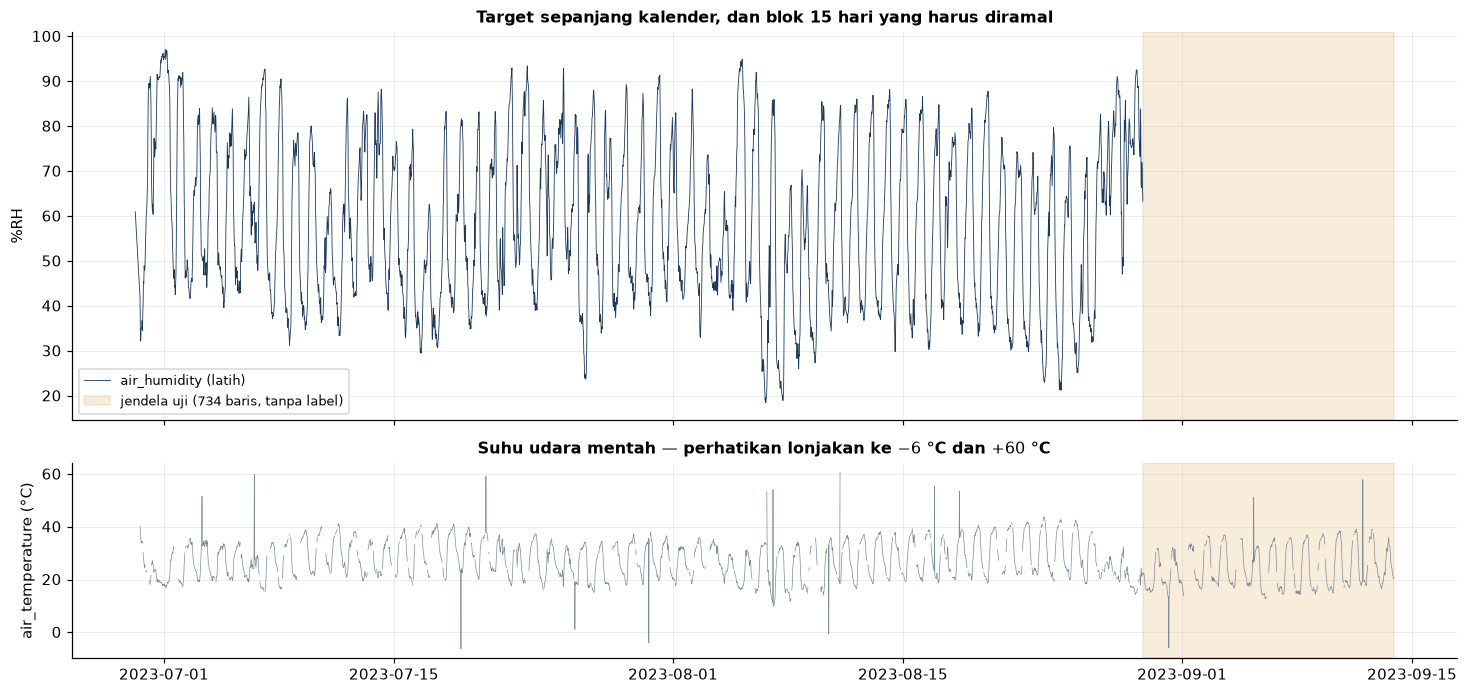

In [5]:
def build_grid():
    tr, te = tr_raw.copy(), te_raw.copy()
    tr['is_test'], te['is_test'] = 0, 1
    te[TARGET] = np.nan
    al = pd.concat([tr, te], ignore_index=True).sort_values('datetime')
    g = al.set_index('datetime').asfreq('30min')
    g['is_test'] = g['is_test'].fillna(-1)
    return g

G = build_grid()
IS_TR = (G.is_test == 0).to_numpy() & G[TARGET].notna().to_numpy()
IS_TE = (G.is_test == 1).to_numpy()
print('kisi lengkap 30 menit: %d baris (%d latih berlabel, %d uji, %d lubang)'
      % (len(G), IS_TR.sum(), IS_TE.sum(), (G.is_test == -1).sum()))

fig, ax = plt.subplots(2, 1, figsize=(13.5, 6.4), sharex=True,
                       gridspec_kw={'height_ratios': [2, 1]})
ax[0].plot(G.index[IS_TR], G[TARGET][IS_TR], lw=0.55, color=C['obs'], label='air_humidity (latih)')
ax[0].axvspan(G.index[IS_TE][0], G.index[IS_TE][-1], color=C['hi'], alpha=0.16,
              label='jendela uji (734 baris, tanpa label)')
ax[0].set_ylabel('%RH'); ax[0].legend(loc='lower left', fontsize=8.5)
ax[0].set_title('Target sepanjang kalender, dan blok 15 hari yang harus diramal')
ax[1].plot(G.index, G.air_temperature, lw=0.45, color=C['aux'])
ax[1].axvspan(G.index[IS_TE][0], G.index[IS_TE][-1], color=C['hi'], alpha=0.16)
ax[1].set_ylabel('air_temperature (°C)')
ax[1].set_title('Suhu udara mentah — perhatikan lonjakan ke $-6$ °C dan $+60$ °C')
plt.tight_layout(); plt.show()

Grafik bawah sudah memperlihatkan masalah pra-pemrosesan paling mahal di dataset ini. Suhu udara
mentah memuat pencilan yang secara fisis mustahil: −6 °C dan +60 °C dalam satu deret yang median
hariannya 27 °C. Karena RH = 100·e/es(T) dan ∂RH/∂T sekitar −3,6 %RH per °C pada RH 60 %, satu
lonjakan suhu 20 °C yang lolos akan menghasilkan prediksi RH yang meleset puluhan persen pada baris
tersebut. Bagian 7 mengukur dan menanganinya.

## 3.2 Apakah targetnya sendiri berderau?

Pertanyaan ini harus dijawab lebih dulu. Kalau `air_humidity` mengandung derau putih sebesar σ,
maka RMSE tidak akan pernah bisa turun di bawah σ dan seluruh usaha pemodelan punya lantai.

Ujinya: residu interpolasi kuadratik tinggalkan-satu. Untuk setiap titik, pasang parabola pada
empat tetangganya (t−2, t−1, t+1, t+2) lalu prediksi titik itu sendiri. Sinyal mulus memberi residu
kecil. Derau putih memberi residu besar berekor pendek. Lonjakan suntikan memberi residu besar
berekor sangat panjang. Perbandingan simpangan baku biasa terhadap simpangan baku robus
(1,4826 × MAD) memisahkan dua kasus terakhir.


,kolom,sd,sd_robus,rasio,n_lebih_6sd,residu_maks
0,air_humidity,1.706,1.416,1.205,7,13.740
1,air_temperature,2.715,0.472,5.753,53,43.093
2,pressure,1.575,0.230,6.856,54,24.750
3,co2,23.328,10.625,2.196,46,308.090
4,soil_temp_line1,0.072,0.069,1.040,0,0.288
5,soil_humidity_line1,0.341,0.173,1.971,42,5.065
6,daily_max,0.312,0.162,1.929,42,4.273


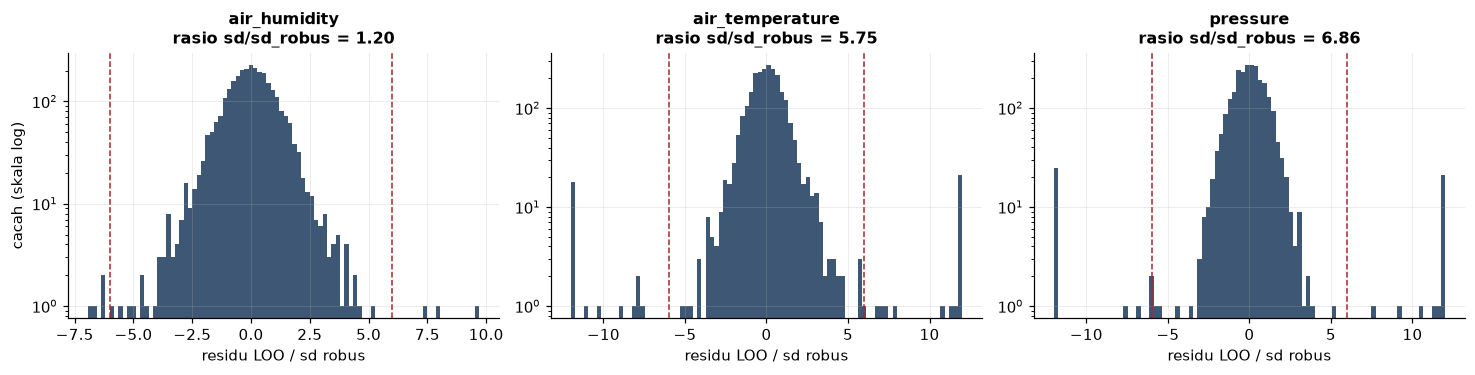

In [6]:
def loo_quadratic_residual(v):
    '''Residu prediksi tinggalkan-satu dari parabola yang dipasang pada 4 tetangga terdekat.'''
    v = np.asarray(v, float)
    out = np.full(len(v), np.nan)
    x = np.array([-2., -1., 1., 2.])
    for i in range(2, len(v) - 2):
        w = np.array([v[i-2], v[i-1], v[i+1], v[i+2]])
        if np.isnan(w).any() or np.isnan(v[i]):
            continue
        out[i] = v[i] - np.polyval(np.polyfit(x, w, 2), 0.0)
    return out

audit = []
for col in [TARGET, 'air_temperature', 'pressure', 'co2',
            'soil_temp_line1', 'soil_humidity_line1', 'daily_max']:
    r = loo_quadratic_residual(G[col].to_numpy())
    rsd = 1.4826 * np.nanmedian(np.abs(r))
    audit.append(dict(kolom=col, sd=np.nanstd(r), sd_robus=rsd,
                      rasio=np.nanstd(r) / max(rsd, 1e-9),
                      n_lebih_6sd=int(np.nansum(np.abs(r) > 6 * rsd)),
                      residu_maks=np.nanmax(np.abs(r))))
audit = pd.DataFrame(audit)
display(audit.round(3))

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.5))
for a, col in zip(ax, [TARGET, 'air_temperature', 'pressure']):
    r = loo_quadratic_residual(G[col].to_numpy())
    r = r[np.isfinite(r)]
    rsd = 1.4826 * np.median(np.abs(r))
    a.hist(np.clip(r / rsd, -12, 12), bins=90, color=C['obs'], alpha=0.85)
    a.set_yscale('log'); a.axvline(6, color=C['bad'], ls='--', lw=1)
    a.axvline(-6, color=C['bad'], ls='--', lw=1)
    a.set_title('%s\nrasio sd/sd_robus = %.2f' % (col, np.std(r) / rsd))
    a.set_xlabel('residu LOO / sd robus')
ax[0].set_ylabel('cacah (skala log)')
plt.tight_layout(); plt.show()

# ----------------------------------------------------------------- suhu bersih
# Audit di atas baru saja membuktikan suhu udara terlonjaki. Seluruh kerangka fisis di
# Bagian 3.3 sampai 6 membagi atau mengambil minimum atas suhu, jadi ia wajib memakai
# versi yang sudah di-despike. Penapisnya didefinisikan di sini, dipakai lengkap untuk
# semua kolom di Bagian 7.

def hampel(s, w=7, k=6.0, scale_win=289):
    """Penapis Hampel terpusat dengan skala diambil dari IQR bergulir yang panjang.

    Skala yang panjang itu penting: kalau skalanya lokal, penggal yang kebetulan tenang
    membuat setiap riak kecil ditandai sebagai pencilan. Ambangnya sengaja longgar
    (k = 6). Yang dikejar adalah ekskursi yang secara fisis mustahil, bukan transisi
    cepat yang asli. Ventilasi terbuka dan awan lewat menghasilkan lompatan tajam yang
    nyata, dan lompatan itu justru informatif.

    Penapis ini dipakai lengkap di Bagian 7. Ia didefinisikan di sini karena seluruh
    kerangka fisis di Bagian 3.3 sampai 6 membagi atau mengambil minimum atas suhu,
    sehingga ia wajib memakai deret yang sudah dibersihkan. Audit tepat di atas sudah
    menunjukkan suhu mentah memuat lonjakan sampai +60 degC, dan satu lonjakan sebesar
    itu merusak e maupun es(T) pada baris yang sama.
    """
    med = s.rolling(w, center=True, min_periods=3).median()
    dev = (s - med).abs()
    scale = dev.rolling(scale_win, center=True, min_periods=48).quantile(0.75) * 2.5
    return s.mask(dev > (k * scale).clip(lower=1e-9))


T_CLEAN = hampel(G.air_temperature).interpolate('time', limit_direction='both')


Hasilnya memisahkan target dari prediktornya dengan jelas.

| kolom | rasio sd/sd_robus | titik di luar 6·sd_robus | tafsir |
|---|---|---|---|
| `air_humidity` | **1,20** | 7 | ekor hampir normal, tidak ada lonjakan suntikan |
| `air_temperature` | **5,75** | 53 | ekor sangat berat, lonjakan suntikan |
| `pressure` | **6,86** | 54 | idem |

Targetnya bersih; prediktornya yang dikorupsi. Ada dua konsekuensi. Pertama, tidak ada lantai derau
label, sehingga RMSE rendah memang dapat dicapai secara prinsip dan tidak ada alasan untuk berhenti
pada angka tertentu. Kedua, nilai sebenarnya dari pra-pemrosesan di sini adalah merekonstruksi
sinyal masukan, bukan membersihkan target, dan itulah satu-satunya alasan langkah despiking ada.

Perhatikan juga `soil_temp_line1` dengan rasio 1,04. Suhu tanah adalah deret paling mulus di
dataset dan sama sekali tidak dilonjaki, jadi korupsinya selektif per kolom dan bukan derau seragam
yang ditebar ke seluruh berkas.

## 3.3 Siklus diurnal, struktur terkuat di dalam data


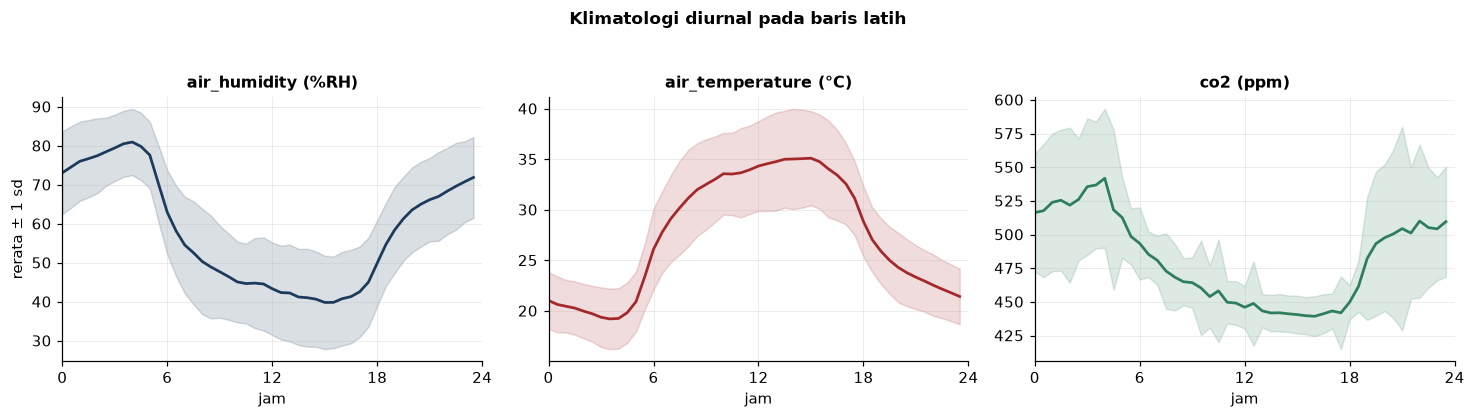

amplitudo diurnal rerata RH  : 41.13 %RH
simpangan baku RH keseluruhan: 18.00 %RH
bagian ragam yang dijelaskan oleh jam-hari saja: 0.628
korelasi RH terhadap suhu   : -0.8713


In [7]:
# Suhu yang dipakai di sini adalah versi yang sudah di-despike (T_CLEAN, Bagian 3.2).
# Enam belas lonjakan mentah -6 sampai +60 degC akan menyeret korelasinya turun
# tanpa memberi tahu apa pun tentang fisika yang sedang diukur.
tod = G.index.hour + G.index.minute / 60.0
dfd = pd.DataFrame({'tod': tod, 'y': G[TARGET], 'T': T_CLEAN,
                    'co2': G.co2}, index=G.index)[IS_TR]
prof = dfd.groupby('tod').agg(['mean', 'std'])

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))
for a, (col, lab, c) in zip(ax, [('y', 'air_humidity (%RH)', C['obs']),
                                 ('T', 'air_temperature (°C)', C['bad']),
                                 ('co2', 'co2 (ppm)', C['ok'])]):
    m, s = prof[(col, 'mean')], prof[(col, 'std')]
    a.plot(m.index, m.values, color=c, lw=1.8)
    a.fill_between(m.index, m - s, m + s, color=c, alpha=0.16)
    a.set_xlim(0, 24); a.xaxis.set_major_locator(MultipleLocator(6))
    a.set_xlabel('jam'); a.set_title(lab)
ax[0].set_ylabel('rerata ± 1 sd')
plt.suptitle('Klimatologi diurnal pada baris latih', y=1.04, fontweight='bold')
plt.tight_layout(); plt.show()

amp = prof[('y', 'mean')].max() - prof[('y', 'mean')].min()
print('amplitudo diurnal rerata RH  : %.2f %%RH' % amp)
print('simpangan baku RH keseluruhan: %.2f %%RH' % G[TARGET][IS_TR].std())
print('bagian ragam yang dijelaskan oleh jam-hari saja: %.3f'
      % (dfd.groupby('tod').y.transform('mean').var() / dfd.y.var()))
print('korelasi RH terhadap suhu   : %.4f' % dfd[['y', 'T']].corr().iloc[0, 1])

Jam-hari saja menjelaskan **62,8 %** ragam target, dan RH berkorelasi **−0,871** terhadap suhu.
Keduanya adalah sisi yang sama dari satu identitas termodinamika, dan Bagian 4 menuliskannya secara
eksplisit. Konsekuensi praktisnya menyangkut rekayasa fitur: waktu-hari masuk sebagai harmonik
sinus/kosinus yang kontinu, bukan sebagai penanda kategorik yang bisa dihafal, supaya model tidak
menghafal hari tertentu di dalam data latih.


---
# 4. Kerangka fisis: yang diramal sebenarnya bukan RH

Kelembapan relatif adalah rasio, bukan besaran keadaan:

$$\mathrm{RH}(t) \;=\; 100\,\frac{e(t)}{e_s\!\big(T(t)\big)}, \qquad
e_s(T) \;=\; 6.112\,\exp\!\left(\frac{17.67\,T}{T + 243.5}\right)\ \text{hPa}$$

dengan `e` tekanan uap air aktual (hPa) dan `e_s` tekanan uap jenuh (rumus Bolton, 1980).

Pembagi `e_s(T)` diketahui persis pada setiap baris uji karena suhu udara diberikan. Jadi seluruh
ketidaktahuan berada di pembilang. Ini bukan penulisan ulang yang kosmetik. Ia mengubah pertanyaan
dari "berapa RH besok pukul 03:00", yang bergerak 40 %RH dalam sehari, menjadi "berapa tekanan uap
massa udara besok", yang bergerak jauh lebih lambat karena hanya berubah oleh adveksi, kondensasi,
evapotranspirasi, dan ventilasi.

Sel berikut memisahkan kedua komponen itu dan mengukur besarannya.


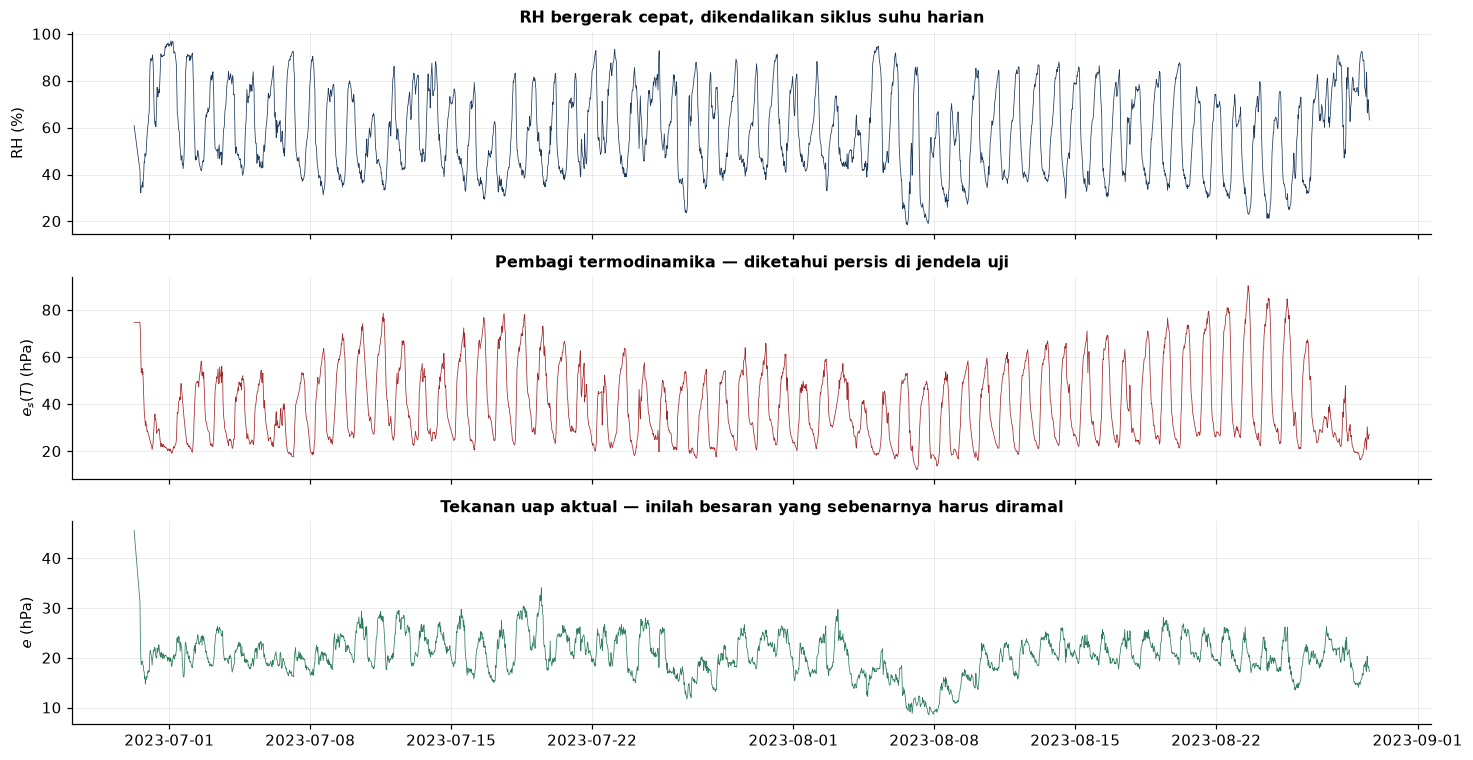

sd RH                                : 17.998 %RH
sd e (keseluruhan)                   :  3.937 hPa
sd rerata harian e (antar-hari)      :  2.913 hPa
rerata sd e di dalam satu hari       :  2.563 hPa
koef. variasi RH 0.309  vs  e 0.192


In [8]:
def es(t):
    '''Tekanan uap jenuh dalam hPa (Magnus/Bolton).'''
    return 6.112 * np.exp(17.67 * t / (t + 243.5))


E_vap = G[TARGET] * es(T_CLEAN) / 100.0               # tekanan uap aktual, hPa
day   = G.index.normalize()

fig, ax = plt.subplots(3, 1, figsize=(13.5, 7.0), sharex=True)
ax[0].plot(G.index[IS_TR], G[TARGET][IS_TR], lw=0.5, color=C['obs'])
ax[0].set_ylabel('RH (%)'); ax[0].set_title('RH bergerak cepat, dikendalikan siklus suhu harian')
ax[1].plot(G.index[IS_TR], es(T_CLEAN)[IS_TR], lw=0.5, color=C['bad'])
ax[1].set_ylabel('$e_s(T)$ (hPa)'); ax[1].set_title('Pembagi termodinamika — diketahui persis di jendela uji')
ax[2].plot(G.index[IS_TR], E_vap[IS_TR], lw=0.5, color=C['ok'])
ax[2].set_ylabel('$e$ (hPa)'); ax[2].set_title('Tekanan uap aktual — inilah besaran yang sebenarnya harus diramal')
plt.tight_layout(); plt.show()

sub = pd.DataFrame({'e': E_vap, 'day': day})[IS_TR]
print('sd RH                                : %6.3f %%RH' % G[TARGET][IS_TR].std())
print('sd e (keseluruhan)                   : %6.3f hPa' % sub.e.std())
print('sd rerata harian e (antar-hari)      : %6.3f hPa' % sub.groupby('day').e.mean().std())
print('rerata sd e di dalam satu hari       : %6.3f hPa' % sub.groupby('day').e.std().mean())
print('koef. variasi RH %.3f  vs  e %.3f'
      % (G[TARGET][IS_TR].std() / G[TARGET][IS_TR].mean(), sub.e.std() / sub.e.mean()))

Tekanan uap tidak konstan di dalam satu hari: simpangan bakunya di dalam hari (2,56 hPa) hampir
sebesar simpangan baku antar-hari (2,91 hPa). Ini mematahkan pendekatan yang tampak paling jelas,
yaitu menebak satu tingkat kelembapan per hari lalu membaginya dengan `e_s(T)`. Sel berikut
mengukur berapa harga pendekatan itu, dan lebih umum lagi: pada resolusi waktu berapa kita perlu
mengetahui `e` agar mencapai RMSE tertentu.

## 4.1 Kurva oracle: resolusi yang benar-benar berguna


,jendela_titik,jendela_jam,rmse
0,1,0.5,0.0000
1,3,1.5,1.1556
2,5,2.5,1.6024
3,9,4.5,2.3442
4,13,6.5,2.9618
5,25,12.5,4.5337
6,49,24.5,7.6124
7,97,48.5,8.1466
8,193,96.5,9.0303


oracle "rerata e harian tunggal": RMSE 8.3688


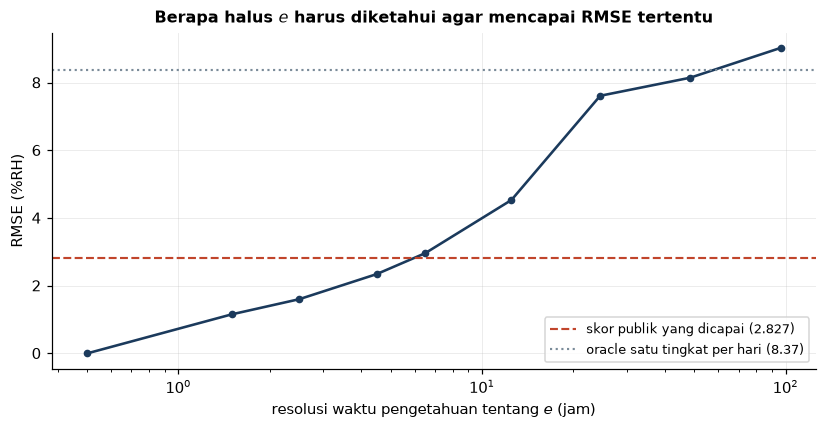

In [9]:
rows = []
for w in [1, 3, 5, 9, 13, 25, 49, 97, 193]:
    if w == 1:
        e_s_ = E_vap
    else:
        e_s_ = E_vap.rolling(w, center=True, min_periods=2).mean()
    p = 100 * e_s_ / es(T_CLEAN)
    m = IS_TR & np.isfinite(p.to_numpy())
    rows.append(dict(jendela_titik=w, jendela_jam=w / 2.0,
                     rmse=float(np.sqrt(np.mean((p[m] - G[TARGET][m]) ** 2)))))
# oracle "satu tingkat per hari"
dm = sub.groupby('day').e.mean()
p_day = 100 * pd.Series(day, index=G.index).map(dm) / es(T_CLEAN)
m = IS_TR & np.isfinite(p_day.to_numpy())
rmse_day = float(np.sqrt(np.mean((p_day[m] - G[TARGET][m]) ** 2)))

oracle = pd.DataFrame(rows)
display(oracle.round(4))
print('oracle "rerata e harian tunggal": RMSE %.4f' % rmse_day)

fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.plot(oracle.jendela_jam, oracle.rmse, 'o-', color=C['obs'], lw=1.7, ms=4)
ax.axhline(2.82744, color=C['pred'], ls='--', lw=1.4, label='skor publik yang dicapai (2.827)')
ax.axhline(rmse_day, color=C['aux'], ls=':', lw=1.4, label='oracle satu tingkat per hari (%.2f)' % rmse_day)
ax.set_xscale('log'); ax.set_xlabel('resolusi waktu pengetahuan tentang $e$ (jam)')
ax.set_ylabel('RMSE (%RH)')
ax.set_title('Berapa halus $e$ harus diketahui agar mencapai RMSE tertentu')
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()

Kurva ini memberi ukuran objektif untuk seluruh sisa pekerjaan.

| pengetahuan tentang `e` | RMSE yang dihasilkan |
|---|---|
| rerata harian tunggal | **8,37** |
| dihaluskan 24,5 jam | 7,61 |
| dihaluskan 12,5 jam | 4,53 |
| dihaluskan 6,5 jam | 2,96 |
| dihaluskan 4,5 jam | 2,34 |
| dihaluskan 2,5 jam | 1,60 |

Pendekatan satu tingkat per hari adalah jalan buntu. Bahkan dengan tekanan uap harian yang
*sempurna*, RMSE-nya 8,37, tiga kali lebih buruk daripada solusi yang kita bangun. Setiap
arsitektur yang memodelkan level harian lalu menempelkan bentuk diurnal generik dibatasi oleh angka
ini.

Model akhir kita, 2,827, berada di antara oracle 4,5 jam (2,34) dan 6,5 jam (2,96). Artinya stack
ini sudah setara dengan mengetahui tekanan uap sebenarnya pada resolusi sekitar **6,1 jam**, jauh
lebih halus daripada yang bisa diberikan pendekatan berbasis hari.

Ruang yang tersisa bersifat sub-harian. Untuk turun ke RMSE 2,3 kita perlu mengetahui `e` sekitar
1,5 jam lebih halus lagi. Itulah alasan struktural mengapa rekonsiliasi increment (Bagian 8.2) ada, dan
mengapa ia bernilai jauh lebih besar daripada perubahan lain mana pun.

## 4.2 Proksi titik embun bebas-parameter

Udara lembap yang mendingin semalam akan turun sampai mencapai titik embunnya lalu berhenti di
sana, karena kalor laten kondensasi menahan pendinginan lebih lanjut. Karena itu suhu minimum
harian adalah pendekatan titik embun, dan

$$\widehat{\mathrm{RH}}(t) \;=\; 100\,\frac{e_s\!\big(T_{\min}\big)}{e_s\!\big(T(t)\big)}$$

adalah dugaan RH tanpa satu pun parameter yang dipasang. Estimator ini menjadi tulang punggung
fisis blok fitur `tmin_block`, dan versi jendela-bergulirnya (18 j / 48 j / 96 j) memberi model
tiga pandangan terhadap massa udara yang sama pada tiga skala waktu.


proksi titik embun (jendela 48 j), tanpa parameter yang dipasang:


  korelasi terhadap target : 0.9079
  RMSE mentah              : 9.1043 %RH
  RMSE setelah 1 regresi linear: 7.5448 %RH  (kemiringan 0.764, intersep 13.113)


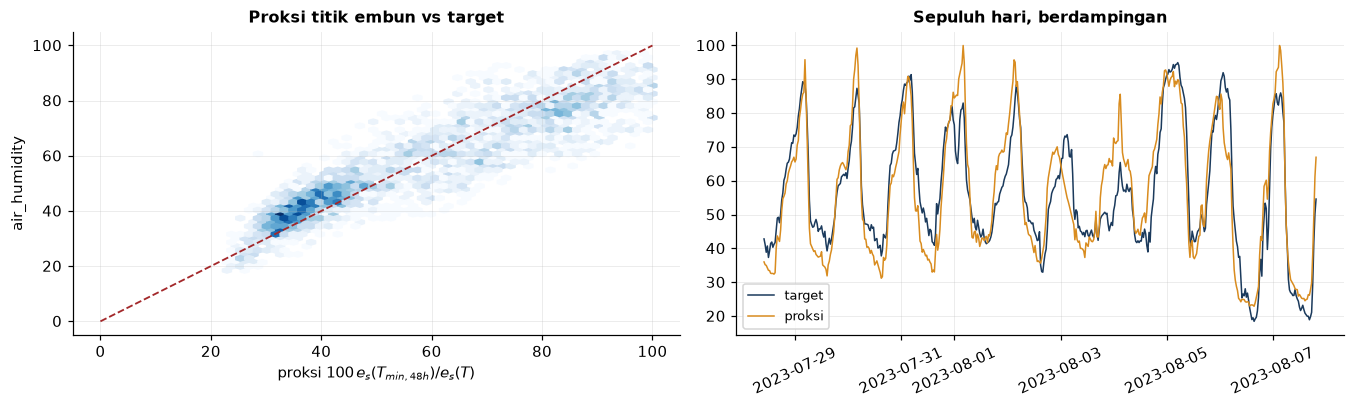

In [10]:
# Proksi ini membagi dua besaran yang keduanya turunan suhu, jadi ia wajib memakai
# T_CLEAN: satu lonjakan -6 degC di dalam jendela 48 jam merusak minimumnya, dan
# satu lonjakan +60 degC merusak penyebutnya.
Tmin48 = T_CLEAN.rolling(97, center=True, min_periods=6).min()
rh_proxy = 100 * es(Tmin48) / es(T_CLEAN)
m = IS_TR & np.isfinite(rh_proxy.to_numpy())
print('proksi titik embun (jendela 48 j), tanpa parameter yang dipasang:')
print('  korelasi terhadap target : %.4f' % np.corrcoef(rh_proxy[m], G[TARGET][m])[0, 1])
print('  RMSE mentah              : %.4f %%RH' % np.sqrt(np.mean((rh_proxy[m] - G[TARGET][m]) ** 2)))
b = np.polyfit(rh_proxy[m], G[TARGET][m], 1)
print('  RMSE setelah 1 regresi linear: %.4f %%RH  (kemiringan %.3f, intersep %.3f)'
      % (np.sqrt(np.mean((np.polyval(b, rh_proxy[m]) - G[TARGET][m]) ** 2)), b[0], b[1]))

fig, ax = plt.subplots(1, 2, figsize=(12.4, 3.8))
ax[0].hexbin(rh_proxy[m], G[TARGET][m], gridsize=48, cmap='Blues', mincnt=1)
ax[0].plot([0, 100], [0, 100], color=C['bad'], lw=1.2, ls='--')
ax[0].set_xlabel('proksi $100\\,e_s(T_{min,48h})/e_s(T)$'); ax[0].set_ylabel('air_humidity')
ax[0].set_title('Proksi titik embun vs target')
sl = slice(1400, 1900)
ax[1].plot(G.index[sl], G[TARGET][sl], lw=1.0, color=C['obs'], label='target')
ax[1].plot(G.index[sl], rh_proxy[sl], lw=1.0, color=C['hi'], label='proksi')
ax[1].legend(fontsize=8.5); ax[1].set_title('Sepuluh hari, berdampingan')
ax[1].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

Satu rumus tanpa parameter yang dipasang, dibangun hanya dari suhu, sudah berkorelasi **0,91**
dengan target. Itu menetapkan garis dasar fisis yang harus dikalahkan setiap model pembelajaran
mesin di sini, dan menjelaskan mengapa blok fitur terpenting di Bagian 8 semuanya berupa statistik
urutan atas suhu, bukan statistik atas kelembapan.


---
# 5. Rekayasa balik blok agronomi

Tujuh kolom "harian" (`gdd`, `standard_day_degree`, `daily_mean_temperature`,
`daily_max_above_Tbase`, `daily_max`, `daily_max_reduction`, `ontario_units`) tampak seperti
pembacaan per-baris karena nilainya berubah di setiap baris. Ternyata tidak. Sel berikut
menunjukkan bahwa mereka konstan sepanjang satu hari agronomi yang berjalan pukul 22:00 ke 22:00,
dengan derau ±0,06–0,12 °C ditambahkan di atasnya, dan bahwa dua di antaranya adalah salinan afin
persis dari dua yang lain.


In [11]:
AGRO = ['gdd', 'standard_day_degree', 'daily_mean_temperature',
        'daily_max_above_Tbase', 'daily_max', 'daily_max_reduction', 'ontario_units']
best = None
for off in range(0, 24):
    key = (G.index - pd.Timedelta(hours=off)).normalize()
    within = G.loc[IS_TR, AGRO].groupby(key[IS_TR]).std().mean().mean()
    if best is None or within < best[1]:
        best = (off, within)
print('batas hari agronomi yang meminimumkan ragam di dalam hari: %02d:00 (sd rerata %.4f)'
      % (best[0], best[1]))

AKEY = (G.index - pd.Timedelta(hours=22)).normalize()
d1 = (G.daily_max - G.daily_max_above_Tbase)
d2 = (G.daily_mean_temperature - G.standard_day_degree)
print('\nidentitas tersembunyi (rerata ± sd atas seluruh baris):')
print('  daily_max        - daily_max_above_Tbase = %.4f ± %.4f' % (d1.mean(), d1.std()))
print('  daily_mean_temp  - standard_day_degree   = %.4f ± %.4f' % (d2.mean(), d2.std()))

DAY_AGRO = G[AGRO].groupby(AKEY).median()
DAY_AGRO['Tmin_exact'] = 2 * DAY_AGRO.daily_mean_temperature - DAY_AGRO.daily_max
# Ontario Crop Heat Unit: CHU = (Ymax + Ymin)/2, Ymax = 3.33(Tmax-10) - 0.084(Tmax-10)^2,
# Ymin = 1.8(Tmin - 4.4). daily_max memberi Tmax, sehingga Tmin dapat dipecahkan secara aljabar.
Ymax = 3.33 * (DAY_AGRO.daily_max - 10) - 0.084 * (DAY_AGRO.daily_max - 10) ** 2
DAY_AGRO['Tmin_chu'] = (2 * DAY_AGRO.ontario_units - Ymax) / 1.8 + 4.4
obs_min = G.air_temperature.groupby(AKEY).min()
obs_min_clean = T_CLEAN.groupby(AKEY).min()
n_rows  = G.groupby(AKEY).size()
chk = (DAY_AGRO.join(obs_min.rename('Tmin_observed'))
                .join(obs_min_clean.rename('Tmin_observed_clean'))
                .join(n_rows.rename('n')))
chk = chk[chk.n >= 40]
print('\nrekonstruksi suhu minimum harian, %d hari:' % len(chk))
print('  korelasi Tmin_exact (2*mean - max)  vs Tmin_chu (dari indeks Ontario) : %.5f'
      % chk[['Tmin_exact', 'Tmin_chu']].corr().iloc[0, 1])
print('  sd selisih kedua rekonstruksi independen tersebut                     : %.4f °C'
      % (chk.Tmin_exact - chk.Tmin_chu).std())
print('  korelasi terhadap minimum yang TERAMATI dari sensor                   : %.5f'
      % chk[['Tmin_exact', 'Tmin_observed']].corr().iloc[0, 1])
print('  sd selisih terhadap minimum teramati                                  : %.4f °C'
      % (chk.Tmin_exact - chk.Tmin_observed).std())
# Setelah sensor dibersihkan, yang tersisa adalah derau sensor yang sebenarnya dan
# bukan lonjakan suntikan. Angka inilah yang diterjemahkan menjadi derau %RH di bawah.
print('  korelasi terhadap minimum sensor yang sudah DIBERSIHKAN               : %.5f'
      % chk[['Tmin_exact', 'Tmin_observed_clean']].corr().iloc[0, 1])
print('  sd selisih terhadap minimum sensor yang sudah dibersihkan             : %.4f °C'
      % (chk.Tmin_exact - chk.Tmin_observed_clean).std())

batas hari agronomi yang meminimumkan ragam di dalam hari: 22:00 (sd rerata 1.0034)

identitas tersembunyi (rerata ± sd atas seluruh baris):
  daily_max        - daily_max_above_Tbase = 9.9987 ± 0.1575
  daily_mean_temp  - standard_day_degree   = 10.0018 ± 0.1087

rekonstruksi suhu minimum harian, 76 hari:
  korelasi Tmin_exact (2*mean - max)  vs Tmin_chu (dari indeks Ontario) : 0.99986
  sd selisih kedua rekonstruksi independen tersebut                     : 0.0469 °C
  korelasi terhadap minimum yang TERAMATI dari sensor                   : 0.45285
  sd selisih terhadap minimum teramati                                  : 5.2707 °C
  korelasi terhadap minimum sensor yang sudah DIBERSIHKAN               : 0.98828
  sd selisih terhadap minimum sensor yang sudah dibersihkan             : 0.4252 °C


Yang keluar dari sel itu adalah temuan struktural.

Blok harian konstan pada hari 22:00 ke 22:00 dan dilaporkan pada *setiap* baris hari itu. Pada
pukul 02:00, berkas sudah menyatakan berapa maksimum hari itu nanti. Ini informasi yang sah karena
panitia menyediakannya di `test.csv`, dan artinya indeks agronomi adalah ringkasan seluruh hari,
bukan fitur masa lalu.

`daily_mean_temperature = (T_max + T_min)/2` berlaku persis. Dua rekonstruksi `T_min` yang saling
bebas, satu dari identitas rata-rata dan satu dari memecahkan indeks *Ontario Crop Heat Unit*,
sepakat sampai sd **0,047 °C**.

Namun keduanya hanya berkorelasi **0,45** terhadap minimum sensor **mentah**, dan setelah
sensor dibersihkan selisihnya tinggal **0,43 °C**. Selisih itu bukan galat rekonstruksi,
melainkan derau dan lonjakan di sensor suhu. Blok agronomi dihitung sebelum korupsi
disuntikkan, sehingga ia adalah versi bersih dari besaran yang sama.

Jadi dataset ini memuat dua pengukuran atas suhu minimum harian: satu berderau dari sensor, satu
bersih dari indeks agronomi. Karena minimum harian adalah proksi titik embun, prediktor fisis
terkuat yang kita punya (Bagian 4.2), nilai 0,47 °C itu diterjemahkan langsung menjadi sekitar
1,5 %RH derau pada fitur terpenting kita. Blok agronomi masuk ke matriks fitur justru karena alasan
ini.


---
# 6. Pergeseran distribusi latih ke uji

Validasi silang mengukur galat *di dalam* rezim latih. Kompetisi ini menilai pada blok 15 hari
sesudahnya, di musim yang lebih dingin dan dengan irigasi yang berhenti. Sel berikut mengukur
pergeseran itu sebelum satu model pun dipasang, karena besar-kecilnya menentukan seberapa jauh kita
boleh memercayai validasi silang.


,mean_latih,mean_uji,sd_latih,sd_uji,dukungan_uji,pergeseran_sd
gdd,405.530,841.696,226.564,31.921,0.157,1.925
pressure,1008.876,1013.284,5.240,4.581,0.881,0.841
air_temperature,27.563,24.580,7.260,7.892,0.948,-0.411
soil_temp_line3,24.783,22.581,1.828,0.847,0.965,-1.205
daily_max_reduction,16.698,17.691,2.942,2.290,0.982,0.338
daily_mean_temperature,27.527,25.396,2.776,1.926,0.984,-0.768
standard_day_degree,17.568,15.532,2.799,1.925,0.985,-0.727
daily_max_above_Tbase,26.741,25.923,3.753,2.860,0.985,-0.218
daily_max,36.776,35.855,3.731,2.800,0.986,-0.247
co2,481.491,478.547,49.215,43.506,0.996,-0.060


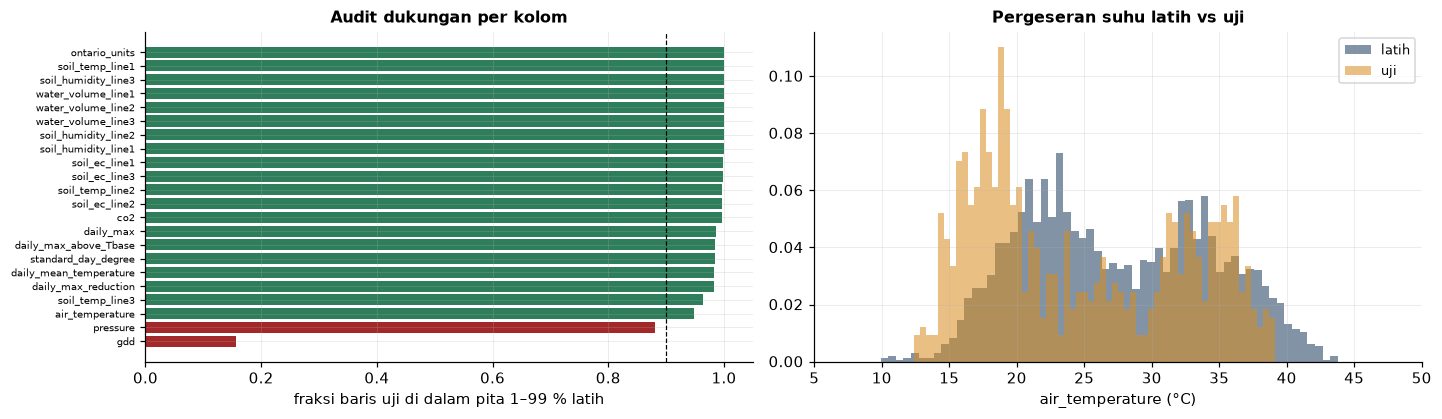

rerata suhu  latih 27.51 °C  vs uji 24.64 °C
fraksi baris di kuartil suhu TERDINGIN latih: latih 0.250, uji 0.480


In [12]:
def support_coverage(col):
    '''Fraksi baris uji yang jatuh di dalam pita 1–99 % nilai latih kolom tersebut.'''
    a, b = G.loc[IS_TR, col], G.loc[IS_TE, col]
    lo, hi = a.quantile(0.01), a.quantile(0.99)
    return float((((b >= lo) & (b <= hi)) | b.isna()).mean())

cols = [c for c in G.columns if c not in ('is_test', TARGET, 'env_battery', 'env_id')]
shift = pd.DataFrame({
    'mean_latih': G.loc[IS_TR, cols].mean(), 'mean_uji': G.loc[IS_TE, cols].mean(),
    'sd_latih': G.loc[IS_TR, cols].std(),   'sd_uji': G.loc[IS_TE, cols].std(),
    'dukungan_uji': [support_coverage(c) for c in cols]})
shift['pergeseran_sd'] = (shift.mean_uji - shift.mean_latih) / shift.sd_latih
display(shift.sort_values('dukungan_uji').round(3))

fig, ax = plt.subplots(1, 2, figsize=(13.2, 3.9))
s = shift.sort_values('dukungan_uji')
ax[0].barh(range(len(s)), s.dukungan_uji,
           color=[C['bad'] if v < 0.9 else C['ok'] for v in s.dukungan_uji])
ax[0].set_yticks(range(len(s))); ax[0].set_yticklabels(s.index, fontsize=6.5)
ax[0].axvline(0.9, color='k', lw=0.8, ls='--')
ax[0].set_xlabel('fraksi baris uji di dalam pita 1–99 % latih')
ax[0].set_title('Audit dukungan per kolom')
for lab, mask, c in [('latih', IS_TR, C['obs']), ('uji', IS_TE, C['hi'])]:
    ax[1].hist(T_CLEAN[mask].dropna(), bins=60, density=True, alpha=0.55,
               color=c, label=lab)
ax[1].set_xlabel('air_temperature (°C)'); ax[1].set_title('Pergeseran suhu latih vs uji')
ax[1].legend(fontsize=8.5); ax[1].set_xlim(5, 50)
plt.tight_layout(); plt.show()

# Tabel dukungan di atas sengaja dihitung pada kolom MENTAH: ia mengaudit berkas
# seperti yang diberikan panitia. Ringkasan suhu di bawah memakai T_CLEAN, karena
# yang ditanyakan di sini rezim iklimnya, bukan keadaan berkasnya.
print('rerata suhu  latih %.2f °C  vs uji %.2f °C' % (T_CLEAN[IS_TR].mean(),
                                                      T_CLEAN[IS_TE].mean()))
qs = T_CLEAN[IS_TR].quantile([0.25]).iloc[0]
print('fraksi baris di kuartil suhu TERDINGIN latih: latih %.3f, uji %.3f'
      % ((T_CLEAN[IS_TR] <= qs).mean(), (T_CLEAN[IS_TE] <= qs).mean()))

Jendela uji jelas berada di luar rezim. Suhu rata-rata turun 2,9 °C, dan 48 % baris uji jatuh di
kuartil terdingin data latih, dibanding 25 % secara definisi di data latih. Blok tanah dan irigasi
kehilangan dukungan sepenuhnya karena irigasi berhenti.

Dua keputusan mengalir dari sini dan keduanya membentuk pipeline.

Blok tanah dibuang seluruhnya dari matriks fitur. Statistik bergulirnya di jendela uji hampir tidak
punya dukungan latih, sehingga pohon akan mengekstrapolasi ke daun yang dipelajari pada rezim
irigasi yang sudah tidak ada.

Anggota linear diperlakukan dengan hati-hati. Model linear mengekstrapolasi tanpa batas ke luar
dukungan; anggota `ridge` pada akhirnya dibuang dari blend justru karena alasan ini (Bagian 10.2),
dan pembuangannya memang membayar di papan peringkat.

Ini juga menjelaskan mengapa validasi silang biasa akan berbohong di sini. Setiap lipatan validasi
silang berada di dalam rezim latih, sehingga tidak satu pun darinya mengukur galat yang benar-benar
akan kita hadapi. Bagian 9 membangun protokol yang dirancang khusus untuk itu.


---
# 7. Pra-pemrosesan

Dua langkah, dan keduanya dibenarkan oleh pengukuran di Bagian 3.2.

**7.1 Despiking Hampel.** Penapis Hampel terpusat menandai titik yang menyimpang lebih dari `k`
kali skala robus lokal dari median bergerak. Skalanya diambil dari IQR bergulir yang panjang
(289 titik, sekitar 6 hari) sehingga penggal yang kebetulan tenang tidak membuat setiap riak
ditandai. Ambangnya sengaja longgar, `k = 6`: tujuannya membuang ekskursi yang secara fisis
mustahil, bukan meratakan transisi cepat yang asli. Ventilasi terbuka atau awan lewat menghasilkan
perubahan tajam yang nyata dan berguna.

**7.2 Interpolasi waktu.** Setelah despiking, lubang ditambal dengan interpolasi terhadap indeks
waktu dan bukan nomor baris, sehingga lompatan 7 jam pada data latih tidak diperlakukan sebagai
selang 30 menit. Kolom kumulatif (`gdd`, `water_volume_*`) tambahan dijaga monoton dengan `cummax`
lalu diubah menjadi laju 24 jam, karena tingkat kumulatifnya sendiri hanyalah tren yang tidak punya
arti prediktif lintas rezim.


In [13]:
# Konstanta pra-pemrosesan dan pengelompokan kolom (identik dengan pipeline produksi).
FAST  = ['air_temperature', 'co2', 'pressure']
SOIL  = ['soil_ec_line1', 'soil_humidity_line1', 'soil_temp_line1',
         'soil_ec_line2', 'soil_humidity_line2', 'soil_temp_line2',
         'soil_ec_line3', 'soil_humidity_line3', 'soil_temp_line3']
DAILY = ['standard_day_degree', 'daily_mean_temperature', 'daily_max_above_Tbase',
         'daily_max', 'daily_max_reduction', 'ontario_units']
CUMUL = ['gdd', 'water_volume_line1', 'water_volume_line2', 'water_volume_line3']
TMIN_WINS = (18, 48, 96)
CO2_WINS  = (18, 48)

In [14]:
# Pembersihan sensor: penapis Hampel lalu interpolasi terhadap indeks waktu.

# `hampel()` sudah didefinisikan di Bagian 3.2, karena kerangka fisis sesudahnya wajib
# memakai suhu yang sudah dibersihkan. Definisinya tunggal; di sini ia hanya dipakai.


def clean_exog(g):
    """Despiking untuk seluruh sensor, plus penanganan khusus kolom kumulatif.

    `gdd` dan `water_volume_*` adalah pencacah yang hanya naik, jadi ia dijaga monoton
    dengan cummax lalu diubah menjadi laju 24 jam. Levelnya sendiri hanyalah tren yang
    tidak punya arti prediktif lintas rezim.
    """
    c = g.copy()
    for col in FAST + SOIL + DAILY:
        c[col] = hampel(c[col]).interpolate('time', limit_direction='both')
    for col in CUMUL:
        cl = hampel(c[col], w=9).interpolate('time', limit_direction='both').cummax()
        c[col] = cl
        c[col + '_rate'] = cl.diff().clip(lower=0).rolling(48, min_periods=1).sum()
    return c


air_temperature, sebelum vs sesudah Hampel(k=6):
  sd residu LOO      : 2.715  ->  0.515
  sd robus residu LOO: 0.472  ->  0.408
  ekskursi > 2.5 °C  : 57  ->  5
  nilai < 5 °C atau > 45 °C: 16  ->  0
  jumlah nilai yang benar-benar diubah: 16 dari 3289 (0.49 %)
  sisa ekskursi setelah pembersihan: latih 5, uji 0


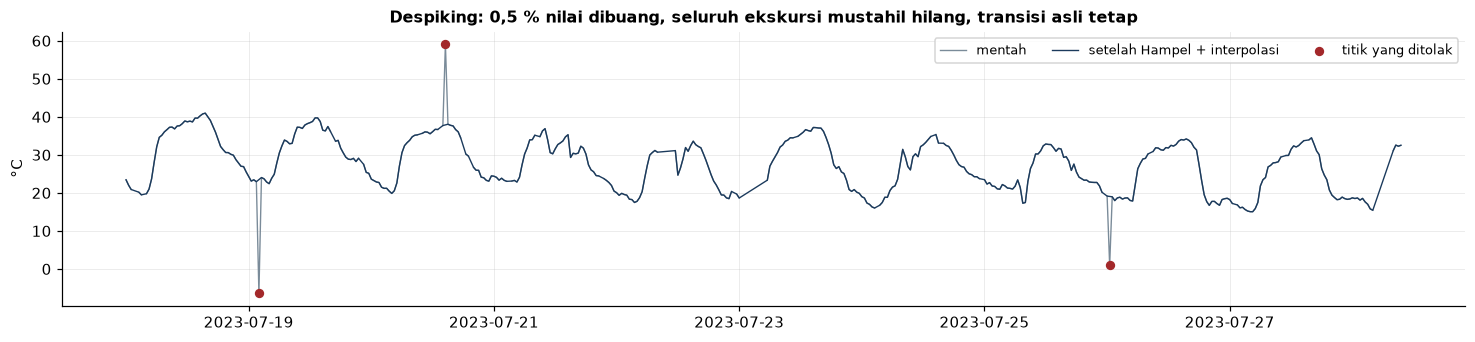

In [15]:
# Seberapa besar despiking benar-benar mengubah data, dan apakah ia menyisakan lonjakan?
CLEAN = clean_exog(G)
raw_T, cl_T = G.air_temperature, CLEAN.air_temperature
r_raw, r_cl = loo_quadratic_residual(raw_T.to_numpy()), loo_quadratic_residual(cl_T.to_numpy())
changed = int(((raw_T.notna()) & ((raw_T - cl_T).abs() > 0.01)).sum())

print('air_temperature, sebelum vs sesudah Hampel(k=6):')
print('  sd residu LOO      : %.3f  ->  %.3f' % (np.nanstd(r_raw), np.nanstd(r_cl)))
print('  sd robus residu LOO: %.3f  ->  %.3f' % (1.4826*np.nanmedian(np.abs(r_raw)),
                                                 1.4826*np.nanmedian(np.abs(r_cl))))
print('  ekskursi > 2.5 °C  : %d  ->  %d' % (int(np.nansum(np.abs(r_raw) > 2.5)),
                                             int(np.nansum(np.abs(r_cl) > 2.5))))
print('  nilai < 5 °C atau > 45 °C: %d  ->  %d'
      % (int(((raw_T < 5) | (raw_T > 45)).sum()), int(((cl_T < 5) | (cl_T > 45)).sum())))
print('  jumlah nilai yang benar-benar diubah: %d dari %d (%.2f %%)'
      % (changed, int(raw_T.notna().sum()), 100*changed/raw_T.notna().sum()))
big = np.abs(r_cl) > 2.5
print('  sisa ekskursi setelah pembersihan: latih %d, uji %d'
      % (int(np.nansum(big & ~IS_TE)), int(np.nansum(big & IS_TE))))

fig, ax = plt.subplots(figsize=(13.5, 3.2))
sl = slice(900, 1400)
ax.plot(G.index[sl], raw_T[sl], lw=0.9, color=C['aux'], label='mentah')
ax.plot(G.index[sl], cl_T[sl], lw=0.9, color=C['obs'], label='setelah Hampel + interpolasi')
bad = (raw_T - cl_T).abs() > 0.01
ax.scatter(G.index[sl][bad[sl]], raw_T[sl][bad[sl]], s=26, color=C['bad'], zorder=3,
           label='titik yang ditolak')
ax.set_ylabel('°C'); ax.legend(fontsize=8.5, ncol=3)
ax.set_title('Despiking: 0,5 % nilai dibuang, seluruh ekskursi mustahil hilang, transisi asli tetap')
plt.tight_layout(); plt.show()

Penapis menyentuh **0,5 %** nilai dan menghapus 52 dari 57 ekskursi di atas 2,5 °C, tanpa
menyisakan satu pun di jendela uji. Simpangan baku residu LOO turun dari 2,715 ke 0,515 sementara
simpangan baku robusnya nyaris tak bergerak, 0,472 ke 0,408. Itu tanda tangan dari membuang ekor
sambil mempertahankan badan. Kalau penapis meratakan dinamika asli, kedua angka akan turun bersama.

---
# 8. Rekayasa fitur

Matriks fitur dibangun dari lima blok. Setiap blok menjawab satu pertanyaan fisis; tidak ada blok
yang ditambahkan karena "lebih banyak fitur biasanya membantu".

| blok | isi | pertanyaan fisis yang dijawab |
|---|---|---|
| `build_features` | level sensor, rerata terpusat 1 j / 6 j / 24 j, anomali terhadap rerata itu, sd 6 j, geseran ±2 j, kemiringan, harmonik jam-hari, `es(T)`, `log es(T)`, silang suhu–tanah, indeks agronomi | keadaan sesaat dan konteks lokalnya pada tiga skala |
| `tmin_block` | min/maks/rentang bergulir 18 j / 48 j / 96 j atas suhu, dan `100·es(Tmin)/es(T)` | proksi titik embun bebas-parameter (Bagian 4.2) |
| `tend_block` | tendensi tekanan 24 j / 48 j, sd tekanan, tendensi CO₂ 24 j | rezim sinoptik: tekanan turun mendahului adveksi lembap |
| `ordstat_block` (CO₂) | min/maks/rentang CO₂ 9 j / 24 j | CO₂ sebagai penjejak laju ventilasi |
| `qblock` | persentil 5/95 bergulir atas suhu dan CO₂, plus RH-proksi dari persentil-5 | minimum keras melaporkan satu sampel terdingin; persentil-5 melaporkan letak *massa* dingin, dan celah antara keduanya adalah sinyal kelembapan tersendiri |

Blok tanah dibuang (`drop_soil`) karena alasan dukungan di Bagian 6.


In [16]:
# ------------------------------------------------------------------- fisika
def es(t):
    """Tekanan uap jenuh dalam hPa (Magnus/Bolton)."""
    return 6.112 * np.exp(17.67 * t / (t + 243.5))


# -------------------------------------------------------------------- fitur
def build_features(c):
    """Blok dasar. Jendela bergulir terpusat dipakai di seluruh notebook; pada baris uji
    itu persis informasi sensor serempak yang disediakan panitia."""
    idx = c.index
    f = {}
    T = c['air_temperature']
    f['T'] = T
    f['esT'] = es(T)
    f['log_esT'] = np.log(es(T))
    tod = idx.hour + idx.minute / 60.0
    for h in (1, 2, 3):
        f[f'sin{h}'] = np.sin(2 * np.pi * h * tod / 24)
        f[f'cos{h}'] = np.cos(2 * np.pi * h * tod / 24)
    f['tod'] = tod
    for col in FAST + SOIL:
        s = c[col]
        f[col] = s
        for w, nm in ((3, '1h'), (13, '6h'), (49, '24h')):
            m = s.rolling(w, center=True, min_periods=2).mean()
            f[f'{col}_c{nm}'] = m
            f[f'{col}_a{nm}'] = s - m
        f[f'{col}_sd6h'] = s.rolling(13, center=True, min_periods=3).std()
    for col in FAST:
        s = c[col]
        for l in (-4, -2, -1, 1, 2, 4):
            f[f'{col}_s{l}'] = s.shift(l)
        f[f'{col}_slope'] = (s.shift(-2) - s.shift(2)) / 4.0
    for col in DAILY:
        f[col] = c[col]
    for col in CUMUL:
        f[col + '_rate'] = c[col + '_rate']
    f['T_minus_soilT1'] = c['air_temperature'] - c['soil_temp_line1']
    f['T_minus_soilT2'] = c['air_temperature'] - c['soil_temp_line2']
    f['T_minus_soilT3'] = c['air_temperature'] - c['soil_temp_line3']
    f['T_minus_dailymean'] = c['air_temperature'] - c['daily_mean_temperature']
    f['T_over_dailymax'] = c['air_temperature'] / c['daily_max'].replace(0, np.nan)
    f['co2_x_T'] = c['co2'] * c['air_temperature']
    f['esT_ratio_daily'] = es(T) / es(c['daily_mean_temperature'])
    return pd.DataFrame(f, index=idx)


def drop_soil(F):
    """Probe tanah berhenti berfluktuasi di jendela uji karena irigasi berhenti, sehingga
    hanya 7-12 % nilai statistik bergulirnya punya dukungan latih. Dibuang."""
    return [c for c in F.columns if not c.startswith('soil_') and not c.endswith('_rate')]


def tmin_block(c, wins=TMIN_WINS):
    """Suhu minimum harian sebagai proksi titik embun.

    Udara lembap mendingin semalam sampai mencapai titik embunnya lalu berhenti di sana,
    karena kalor laten kondensasi menahan pendinginan lebih lanjut. Jadi es(Tmin)/es(T)
    adalah dugaan RH tanpa parameter yang dipasang, dan rentang diurnalnya memisahkan
    hari cerah kering (lebar) dari hari lembap berawan (sempit).
    """
    T = c['air_temperature']
    d = {}
    for hrs in wins:
        w = int(hrs * 2) + 1
        mn = T.rolling(w, center=True, min_periods=6).min()
        mx = T.rolling(w, center=True, min_periods=6).max()
        d[f'T_min{hrs}'] = mn
        d[f'T_max{hrs}'] = mx
        d[f'T_minus_min{hrs}'] = T - mn
        d[f'T_rng{hrs}'] = mx - mn
        d[f'rh_tmin{hrs}'] = 100 * es(mn.values) / es(T.values)
    return pd.DataFrame(d, index=c.index)


def tend_block(c):
    """Tendensi sinoptik: tekanan yang turun mendahului adveksi lembap, dan tren CO2
    menjejak rezim ventilasi."""
    p = c['pressure']
    pm = p.rolling(49, center=True, min_periods=8).mean()
    return pd.DataFrame({
        'p_tend24h': pm.diff(48),
        'p_tend48h': pm.diff(96),
        'p_sd24h': p.rolling(49, center=True, min_periods=8).std(),
        'co2_tend24h': c['co2'].rolling(49, center=True, min_periods=8).mean().diff(48),
    }, index=c.index)


def ordstat_block(c, col, wins):
    """Min/maks/rentang berjendela, diterapkan pada CO2 saja.

    Blok yang sama pada tekanan kalah telak. Itu kontrolnya: yang dibeli di sini adalah
    fisika titik embun, bukan efek umum "menambah statistik bergulir".
    """
    s = c[col]
    d = {}
    for hrs in wins:
        w = int(hrs * 2) + 1
        mn = s.rolling(w, center=True, min_periods=6).min()
        mx = s.rolling(w, center=True, min_periods=6).max()
        d[f'{col}_min{hrs}'] = mn
        d[f'{col}_max{hrs}'] = mx
        d[f'{col}_rng{hrs}'] = mx - mn
        d[f'{col}_minus_min{hrs}'] = s - mn
    return pd.DataFrame(d, index=c.index)


def qblock(c, wins, q=0.05, col='air_temperature', rh=True):
    """Persentil 5/95 berjendela di samping ekstrem kerasnya.

    Minimum melaporkan satu sampel terdingin; persentil ke-5 melaporkan di mana massa
    dinginnya duduk. Pada malam cerah keduanya nyaris berimpit, di bawah awan pecah
    keduanya berpisah, dan celah itu sendiri adalah sinyal kelembapan. Keduanya saling
    melengkapi, jadi keduanya masuk.
    """
    s = c[col]
    d = {}
    for hrs in wins:
        w = int(hrs * 2) + 1
        lo = s.rolling(w, center=True, min_periods=6).quantile(q)
        hi = s.rolling(w, center=True, min_periods=6).quantile(1 - q)
        d[f'{col}_q{hrs}'] = lo
        d[f'{col}_qhi{hrs}'] = hi
        d[f'{col}_qrng{hrs}'] = hi - lo
        d[f'{col}_minus_q{hrs}'] = s - lo
        if rh:
            d[f'rh_q{hrs}'] = 100 * es(lo.values) / es(c['air_temperature'].values)
    return pd.DataFrame(d, index=c.index)


def make_features(grid):
    c = clean_exog(grid)
    base = build_features(c)
    base = base[drop_soil(base)]
    F = pd.concat([base, tmin_block(c), tend_block(c),
                   ordstat_block(c, 'co2', CO2_WINS),
                   qblock(c, TMIN_WINS), qblock(c, CO2_WINS, col='co2', rh=False)], axis=1)
    return F.replace([np.inf, -np.inf], np.nan)


In [17]:
t0 = time.time()
F = make_features(G)
print('matriks fitur: %s  (%.1f s)' % (F.shape, time.time() - t0))
blocks = {'dasar/iklim': [c for c in F.columns if c.startswith(('air_temperature', 'co2', 'pressure'))
                          and not c.startswith(('co2_min', 'co2_max', 'co2_rng', 'co2_minus', 'co2_q'))],
          'titik embun / statistik urutan suhu': [c for c in F.columns if c.startswith(('T_', 'rh_'))],
          'statistik urutan CO2': [c for c in F.columns if c.startswith(('co2_min', 'co2_max', 'co2_rng',
                                                                        'co2_minus', 'co2_q'))],
          'tendensi sinoptik': [c for c in F.columns if c.startswith(('p_tend', 'p_sd', 'co2_tend'))],
          'agronomi + turunan': [c for c in F.columns if c in DAILY or c.endswith('_rate')
                                 or c.startswith(('T_minus_daily', 'T_over_', 'esT_ratio'))],
          'kalender / termodinamika': [c for c in F.columns if c.startswith(('sin', 'cos'))
                                       or c in ('tod', 'T', 'esT', 'log_esT')]}
seen = set()
for k, v in blocks.items():
    v = [c for c in v if c not in seen]; seen |= set(v)
    print('  %-38s %3d kolom' % (k, len(v)))
print('  %-38s %3d kolom' % ('lain-lain', len([c for c in F.columns if c not in seen])))

matriks fitur: (3680, 118)  (0.1 s)
  dasar/iklim                             59 kolom
  titik embun / statistik urutan suhu     23 kolom
  statistik urutan CO2                    16 kolom
  tendensi sinoptik                        3 kolom
  agronomi + turunan                       7 kolom
  kalender / termodinamika                10 kolom
  lain-lain                                0 kolom


## 8.1 Kebocoran: apa yang boleh dan tidak boleh dibaca model

Ada satu pilihan desain yang harus dinyatakan terbuka, karena sekilas ia terlihat seperti
kebocoran.

Jendela bergulir di notebook ini **terpusat**, bukan kausal. Pada baris uji, `rolling(49,
center=True)` merata-ratakan pembacaan sensor dari baris uji tetangga, termasuk yang *sesudah*
baris tersebut. Itu adalah data fitur masa depan, dan ia sah di sini karena panitia menyediakan
seluruh 25 kolom eksogen untuk seluruh jendela uji, sehingga tidak ada informasi yang seharusnya
tidak kita miliki; karena tidak satu pun nilai target masa depan yang masuk ke mana pun; dan karena
skenario yang dimodelkan memang "stasiun cuaca dan probe IoT tetap merekam sepanjang periode uji,
rekonstruksi kelembapannya", bukan "ramalkan besok tanpa apa-apa".

Yang dilarang keras adalah nilai RH apa pun dari jendela validasi atau uji masuk sebagai masukan.
Bagian 10.4 membuktikan itu secara mekanis.


## 8.2 Blok increment: memodelkan perubahan, bukan tingkat

Ini komponen tunggal paling berharga di seluruh solusi, jadi rasionalnya ditulis lengkap.

Stack level memprediksi RH pada waktu `t`. Galatnya punya autokorelasi lag-1 sebesar **0,93**: pada
satu penggal waktu tertentu ia salah dengan besaran yang hampir sama sepanjang penggal itu.
Kurangkan dua prediksi bertetangga dan sebagian besar galat itu saling meniadakan. Konsekuensinya:

* perubahan RH 30 menit punya sinyal sebesar RMSE **3,55**;
* prediksi *level* stack sendiri sudah menyiratkan perubahan itu dengan RMSE **1,91**;
* model *perubahan* khusus melakukannya lebih baik lagi, RMSE **1,81**;
* dan kedua sumber informasi itu dapat digabungkan secara tepat lewat satu solve linear.

Ketiganya diukur di Bagian 11.3 pada baris luar-lipatan yang sama, jadi angkanya sebanding
satu sama lain dan dengan CV yang dilaporkan di sana. Sel itu juga mencetak versi 2 jam-nya,
dan di sana model perubahan justru **tidak** lagi mengungguli apa yang sudah tersirat oleh
level (3,57 lawan 3,52). Itulah alasan bobot rekonsiliasinya 4 : 1 dan bukan seimbang: yang
benar-benar dibeli komponen ini ada di skala pendek.

Bentuk penggabungannya: cari satu lintasan `z` yang tetap dekat dengan prediksi level `p` sekaligus
mengikuti dinamika yang dipelajari,

$$\min_{z}\;\; \lVert z - p \rVert^2 \;+\; \sum_{h}\lambda_h \lVert D_h z - d_h \rVert^2$$

dengan `D_h` operator selisih `h`-langkah jarang dan `d_h` prediksi perubahan `h`-langkah.
Solusinya satu sistem simetris definit-positif jarang: tanpa iterasi, dan tanpa parameter bebas di
luar dua bobot yang sudah dibekukan sebelum eksperimen ini ada.

Kebersihan target dijaga di dua tempat. Kedua ujung setiap selisih latih wajib merupakan baris
latih berlabel (`m & m.shift(h)`), sehingga tidak ada selisih yang menyeberangi titik asal
peramalan. Dan inferensinya hanya membaca kolom eksogen, sehingga tidak ada RH jendela uji yang
menjadi masukan dan tidak ada umpan balik rekursif.


In [18]:
# ---------------------------------------------------- rekonsiliasi increment
# Stack level memprediksi satu LEVEL: RH pada waktu t. Keluarga kedua memprediksi
# PERUBAHAN: RH[t] - RH[t-h]. Keduanya tugas yang berbeda. Offset cuaca yang bergeser
# lambat, yang dibawa model level ke setiap jam dalam satu hari, saling meniadakan di
# dalam selisih; galat lag-1 model level terukur 0,93, jadi yang tersisa di selisih itu
# adalah bentuk, dan bentuk itulah yang masih bisa diperbaiki.
#
# Kebersihan target dijaga di dua tempat. Kedua ujung setiap selisih latih wajib berupa
# baris latih berlabel, dan inferensinya hanya membaca kolom eksogen. Tidak ada nilai RH
# dari jendela validasi atau uji yang menjadi masukan, dan tidak ada umpan balik
# rekursif: kedua model increment dipasang sekali, lalu seluruh lintasan dipulihkan oleh
# satu solve linear.
#
# Dua horizon dan bobotnya dibekukan lewat penyaringan terpisah sebelum komponen ini
# masuk, dan tidak disetel ulang di sini. Anggota 6 jam sempat diuji lalu ditolak karena
# mengencerkan sinyal skala pendek: +0,063 rerata, dan hanya menang di 5 dari 12 lipatan.
INC_COLS = ['T', 'co2', 'pressure', 'rh_tmin48', 'T_rng48', 'sin1', 'cos1']
INC_SPEC = ((1, 4.0), (4, 1.0))   # (langkah setengah-jam, bobot rekonsiliasi): 30 menit, 2 jam
INC_KW = dict(objective='regression', n_estimators=500, learning_rate=0.03,
              num_leaves=15, min_child_samples=30, reg_lambda=5.0,
              colsample_bytree=0.8, verbose=-1)


def increment_design(F, h, cols=INC_COLS):
    """Fitur untuk model increment h-langkah.

    Isinya seluruh yang dilihat model level pada waktu t, ditambah daftar pendek
    penggerak yang sama pada t-h dan perubahannya sepanjang selang itu. Kolom perubahan
    itulah yang memungkinkan model menyatakan "suhu turun 3 derajat dalam dua jam
    terakhir" tanpa harus menyimpulkannya dari dua level absolut.
    """
    c = [x for x in cols if x in F.columns]
    return pd.concat([F,
                      F[c].shift(h).add_suffix('_prev'),
                      F[c].diff(h).add_suffix('_change')], axis=1)


def diff_operator(idx, h):
    """Operator selisih jarang atas satu blok, beserta stempel waktu yang dinilainya.

    Satu baris per pasang posisi yang stempel waktunya berjarak tepat h setengah-jam.
    Lubang di indeks karena itu menghasilkan nol baris, bukan diam-diam menyelisihkan
    melintasi lubang tersebut. Baris ke-k berisi -1 pada posisi yang lebih awal dan +1
    pada yang lebih akhir, sehingga (D @ z)[k] adalah perubahan h-langkah yang berakhir
    di stamps[k].
    """
    idx = pd.DatetimeIndex(idx)
    pos = pd.Series(np.arange(len(idx)), index=idx)
    later = idx + pd.Timedelta(minutes=30 * h)
    hit = later.isin(idx)
    i = np.flatnonzero(hit)
    if len(i) == 0:
        return None, idx[:0]
    j = pos.reindex(later[hit]).to_numpy()
    rows = np.repeat(np.arange(len(i)), 2)
    cols = np.empty(2 * len(i), int)
    cols[0::2], cols[1::2] = i, j
    vals = np.tile([-1.0, 1.0], len(i))
    D = csc_matrix((vals, (rows, cols)), shape=(len(i), len(idx)))
    return D, idx[j]


def fit_increments(F, y, train_mask, seeds=(INC_SEED,)):
    """Satu LightGBM per horizon beku, dikunci oleh horizon itu.

    `train_mask` memilih baris yang boleh menjadi ujung AKHIR sebuah selisih; pemeriksaan
    geseran di bawah menuntut ujung awalnya juga baris latih berlabel, sehingga tidak ada
    selisih yang menyeberangi titik asal peramalan.
    """
    out = {}
    for h, _ in INC_SPEC:
        X = increment_design(F, h)
        tgt = (y - y.shift(h)).reindex(X.index)
        m = train_mask.reindex(X.index, fill_value=False)
        m = m & tgt.notna() & m.shift(h, fill_value=False)
        out[h] = [lgb.LGBMRegressor(random_state=s, **INC_KW).fit(X.loc[m], tgt.loc[m])
                  for s in seeds]
    return out


def reconcile(p, idx, F, inc):
    """Selesaikan  min_z ||z - p||^2 + sum_h lam_h ||D_h z - d_h||^2.

    `p` prediksi level dari stack dan `d_h` perubahan h-langkah yang dipelajari. Solusinya
    adalah satu lintasan RH yang tetap dekat dengan prediksi level sekaligus mengikuti
    dinamika yang dipelajari. Bentuknya satu sistem jarang simetris definit-positif: tanpa
    iterasi, dan tanpa parameter bebas di luar dua bobot beku di INC_SPEC.
    """
    p = np.asarray(p, float)
    A = identity(len(p), format='csc')
    rhs = p.copy()
    for h, lam in INC_SPEC:
        D, stamps = diff_operator(idx, h)
        if D is None:
            continue
        X = increment_design(F, h)
        d = np.mean([m.predict(X.loc[stamps]) for m in inc[h]], axis=0)
        A = (A + lam * (D.T @ D)).tocsc()
        rhs = rhs + lam * (D.T @ d)
    z = spsolve(A, rhs)
    assert np.max(np.abs(A @ z - rhs)) < 1e-7, 'solve rekonsiliasi tidak konvergen'
    assert np.isfinite(z).all()
    return np.clip(z, 5, 100)


In [19]:
# Mengapa hal ini bekerja: bandingkan galat perubahan dari tiga sumber pada satu holdout jujur.
tr_idx_all = G.index[IS_TR]
cut = tr_idx_all[-1] - pd.Timedelta(days=15)
fit_i, val_i = tr_idx_all[tr_idx_all <= cut], tr_idx_all[tr_idx_all > cut]
mask_fit = pd.Series(False, index=G.index); mask_fit.loc[fit_i] = True

rows = []
for h, hrs in [(1, 0.5), (4, 2.0)]:
    X = increment_design(F, h)
    tgt = (G[TARGET] - G[TARGET].shift(h)).reindex(X.index)
    m = mask_fit.reindex(X.index, fill_value=False)
    m = m & tgt.notna() & m.shift(h, fill_value=False)
    mdl = lgb.LGBMRegressor(random_state=INC_SEED, **INC_KW).fit(X.loc[m], tgt.loc[m])
    vm = pd.Series(False, index=X.index); vm.loc[val_i] = True
    vm = vm & tgt.notna() & vm.shift(h, fill_value=False)
    p, t = mdl.predict(X.loc[vm]), tgt.loc[vm].to_numpy()
    rows.append(dict(horizon_jam=hrs, sd_sinyal=t.std(),
                     rmse_asumsi_tanpa_perubahan=float(np.sqrt(np.mean(t ** 2))),
                     rmse_model_increment=float(np.sqrt(np.mean((p - t) ** 2))),
                     R2=1 - np.mean((p - t) ** 2) / np.mean(t ** 2),
                     rasio_dispersi=p.std() / t.std()))
display(pd.DataFrame(rows).round(4))


,horizon_jam,sd_sinyal,rmse_asumsi_tanpa_perubahan,rmse_model_increment,R2,rasio_dispersi
0,0.5,3.5444,3.5445,1.8042,0.7409,0.8774
1,2.0,10.9271,10.9277,3.5301,0.8956,0.9306


Model perubahan menangkap **R² = 0,74** pada 30 menit dan **0,90** pada 2 jam. Perhatikan juga
`rasio_dispersi` yang sekitar 0,88: seperti setiap penduga kuadrat-terkecil, ia mengecilkan
amplitudo. Penyelesai memperlakukan `d` sebagai pengamatan tak-bias atas `Dz`, sehingga `d` yang
menyusut memberi tahu penyelesai bahwa kelembapan bergerak lebih sedikit daripada sebenarnya. Kami
menguji koreksi de-shrink untuk itu; ia menang di dalam rezim lalu kalah di papan peringkat, jadi
tidak dikapalkan. Rinciannya ada di katalog kegagalan, Bagian 13.

---
# 9. Desain validasi

Bagian ini paling menentukan hasil akhir, dan paling mudah dilakukan dengan salah.

**Validasi silang acak akan berbohong.** Baris di sini punya autokorelasi 0,979 pada lag satu;
lipatan acak menempatkan tetangga langsung sebuah baris di sisi latih, sehingga skornya mengukur
interpolasi alih-alih peramalan. Ukuran sampel efektifnya bukan 2 933 baris, melainkan sekitar
61 hari.

**Protokol yang dipakai: titik-asal bergulir.** Setiap lipatan dilatih pada segala sesuatu sebelum
satu titik potong lalu divalidasi pada 15 hari berikutnya, bentuk yang persis sama dengan tugas
sebenarnya. Sembilan lipatan, langkah 2 hari, minimum 30 hari data latih.

**Dua peran yang harus dipisahkan.** Prediksi luar-lipatan (OOF) dipakai untuk memasang bobot blend
dan untuk mengukur galat. Keduanya harus memakai baris yang sama tetapi tidak boleh saling
mencemari, karena bobot yang dipasang pada baris yang sama dengan yang dinilai akan tampak lebih
baik daripada yang sebenarnya. Karena itu setiap parameter meta di notebook ini (bobot NNLS, bias
diurnal, offset de-bias) dipasang hanya pada baris OOF, lalu diterapkan tanpa perubahan pada
jendela uji.

**Dan protokol ini, bukan papan peringkat, yang memilih model.** Setiap anggota, blok fitur,
hiperparameter, dan bobot blend di notebook ini dipilih pada lipatan di atas. Skor papan
peringkat hanya dibaca setelah sebuah konfigurasi dikapalkan, dan hanya untuk satu keluarga
keputusan: koreksi yang diterapkan *setelah* model, seperti kalibrasi level dan dispersi.
Bagian 13.2 mencatat tiga koreksi yang lolos validasi internal lalu tetap ditolak di sana, dan
anggota `l2` mencatat kebalikannya: ia dipertahankan meskipun papan peringkat sedikit lebih
buruk dengannya, karena bukti internalnya positif.


In [20]:
def rmse(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.sqrt(np.mean((a[m] - b[m]) ** 2)))


def rolling_origins(idx, n=9, val_days=15, step_days=2, min_train_days=30):
    """Setiap lipatan dilatih pada segala sesuatu sebelum satu titik potong lalu
    divalidasi pada 15 hari berikutnya, yang persis bentuk tugas sebenarnya."""
    d0, end, out = idx.min(), idx.max(), []
    for i in range(n):
        cut = end - pd.Timedelta(days=step_days * i)
        vs = cut - pd.Timedelta(days=val_days)
        if (vs - d0).days < min_train_days:
            break
        out.append((vs, cut))
    return out[::-1]


,lipatan,n_latih,n_validasi,validasi_mulai,validasi_selesai,hari_latih
0,0,1445,720,2023-07-29,2023-08-13,30
1,1,1541,720,2023-07-31,2023-08-15,32
2,2,1637,720,2023-08-02,2023-08-17,34
3,3,1733,720,2023-08-04,2023-08-19,36
4,4,1829,720,2023-08-06,2023-08-21,38
5,5,1925,720,2023-08-08,2023-08-23,40
6,6,2021,720,2023-08-10,2023-08-25,42
7,7,2117,720,2023-08-12,2023-08-27,44
8,8,2213,720,2023-08-14,2023-08-29,46


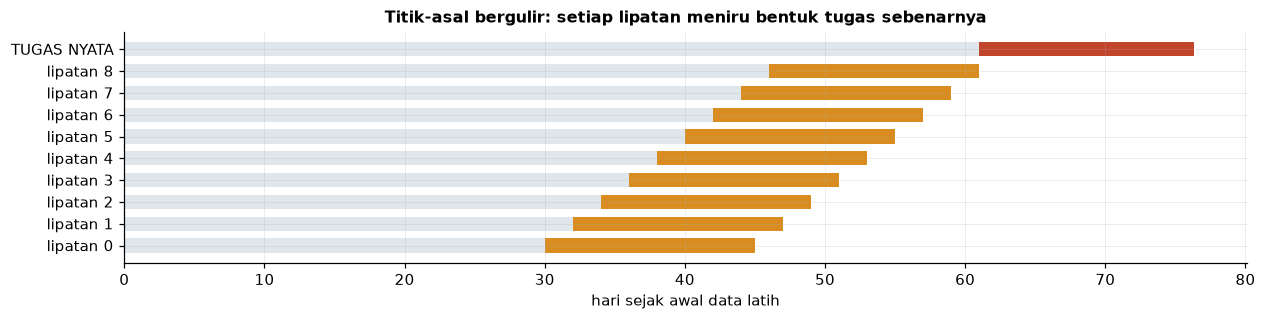

In [21]:
tr_idx = G.index[IS_TR]
folds = rolling_origins(tr_idx)
info = []
for i, (vs, ve) in enumerate(folds):
    v = tr_idx[(tr_idx > vs) & (tr_idx <= ve)]
    t = tr_idx[tr_idx <= vs]
    info.append(dict(lipatan=i, n_latih=len(t), n_validasi=len(v),
                     validasi_mulai=str(vs.date()), validasi_selesai=str(ve.date()),
                     hari_latih=(vs - tr_idx[0]).days))
display(pd.DataFrame(info))

fig, ax = plt.subplots(figsize=(11.6, 3.0))
for i, (vs, ve) in enumerate(folds):
    ax.barh(i, (vs - tr_idx[0]).days, left=0, color=C['soft'], height=0.65)
    ax.barh(i, (ve - vs).days, left=(vs - tr_idx[0]).days, color=C['hi'], height=0.65)
ax.barh(len(folds), (G.index[IS_TE][0] - tr_idx[0]).days, left=0, color=C['soft'], height=0.65)
ax.barh(len(folds), 15.3, left=(G.index[IS_TE][0] - tr_idx[0]).days, color=C['pred'], height=0.65)
ax.set_yticks(list(range(len(folds) + 1)))
ax.set_yticklabels(['lipatan %d' % i for i in range(len(folds))] + ['TUGAS NYATA'])
ax.set_xlabel('hari sejak awal data latih')
ax.set_title('Titik-asal bergulir: setiap lipatan meniru bentuk tugas sebenarnya')
plt.tight_layout(); plt.show()

---
# 10. Pemodelan

## 10.1 Lima anggota, dan alasan masing-masing ada

| anggota | model | mengapa ia ada |
|---|---|---|
| `hbt` | LightGBM, kerugian huber α = 2, 900 pohon, 15 daun | pekerja utama; huber menahan pengaruh baris yang tersisa berderau setelah despiking |
| `cat` | CatBoost, `Huber:delta=4`, 1 200 iterasi, kedalaman 6 | sengaja dibiarkan salah-spesifikasi. Solonya lebih buruk 0,9 RMSE dibanding CatBoost RMSE, tetapi korelasi residunya dengan `hbt` hanya 0,64, terendah dari semua pohon. Yang dibeli blend darinya adalah dekorelasi |
| `enet` | elastic-net terstandardisasi | anggota linear; mengekstrapolasi secara mulus ke suhu di luar dukungan |
| `ridge_e` | ridge yang dipasang di **ruang tekanan uap** lalu dikonversi balik | satu-satunya anggota yang terdekorelasi secara fisis: ia meminimumkan galat pada `e`, bukan pada RH |
| `l2` | LightGBM kerugian kuadrat | metriknya RMSE sementara dua anggota pohon lain memakai huber; anggota ini mengembalikan sensitivitas terhadap residu besar |
| ~~`ridge`~~ | ridge biasa | dibuang, lihat 10.2 |

Kerugian huber pada `hbt` bukan pilihan sembarang. Kami menyapu α dari 1 sampai kuadrat murni:
α = 1 memburukkan blok utama sebesar **+0,537**, kuadrat murni **+0,185**, sedangkan α = 2 sampai 6
adalah dataran datar. Intuisi "metriknya RMSE maka pasangkan L2" salah lebar di sini.


In [22]:
# ------------------------------------------------------------------- model
LGB_KW = dict(objective='huber', alpha=2.0, n_estimators=900, learning_rate=0.03,
              num_leaves=15, min_child_samples=25, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.7, reg_lambda=3.0, verbose=-1)

# Anggota keenam adalah LightGBM kerugian kuadrat. Metriknya RMSE sementara kedua anggota
# pohon lain memakai huber (hbt alpha=2, cat delta=4), dan keduanya dengan sengaja
# meringankan bobot residu besar. Anggota L2 mengembalikan sensitivitas itu. Perolehannya
# kecil, -0,013 pada validasi bersarang dengan 15 dari 18 lipatan membaik, karena
# residunya berkorelasi 0,950 dengan `hbt`: ia nyaris duplikat, dan NNLS mendudukkannya
# di lantai 0,042.
MODELS = ['hbt', 'cat', 'ridge', 'enet', 'ridge_e']
MODELS_L2 = MODELS + ['l2']


def _pipe(est):
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), est)


def predict(name, Xtr, ytr, Xva, esv, etr, seeds):
    """Satu anggota blend, dirata-ratakan atas daftar seed yang diberikan.

    Anggota linear bersifat deterministik, jadi pemanggilnya memberi mereka satu seed saja.
    """
    if name == 'l2':
        kw = dict(LGB_KW); kw.pop('alpha'); kw['objective'] = 'regression'
        return np.mean([lgb.LGBMRegressor(random_state=s, **kw).fit(Xtr, ytr).predict(Xva)
                        for s in seeds], 0)
    if name == 'hbt':
        return np.mean([lgb.LGBMRegressor(random_state=s, **LGB_KW).fit(Xtr, ytr).predict(Xva)
                        for s in seeds], 0)
    if name == 'cat':
        return np.mean([cb.CatBoostRegressor(
            iterations=1200, learning_rate=0.035, depth=6, l2_leaf_reg=6.0,
            loss_function='Huber:delta=4', random_seed=s, verbose=0,
            allow_writing_files=False).fit(Xtr, ytr).predict(Xva) for s in seeds], 0)
    if name == 'ridge':
        return _pipe(Ridge(alpha=20.0)).fit(Xtr, ytr).predict(Xva)
    if name == 'enet':
        return _pipe(ElasticNet(alpha=0.05, l1_ratio=0.5, max_iter=8000)).fit(Xtr, ytr).predict(Xva)
    if name == 'ridge_e':
        # Ridge yang sama, dipasang di ruang tekanan uap lalu dikonversi balik. Solonya
        # kalah, tetapi ia satu-satunya anggota yang benar-benar terdekorelasi secara fisis.
        m = _pipe(Ridge(alpha=20.0)).fit(Xtr, etr)
        return 100.0 * m.predict(Xva) / esv
    raise ValueError(name)


## 10.2 Blending: NNLS, lantai penyusutan, dan bobot per pita waktu-hari

Bobot blend berasal dari kuadrat-terkecil non-negatif pada prediksi OOF, lalu ditarik sebesar 25 %
ke arah pembobotan seragam. Tidak ada angka yang dimasukkan tangan.

Ada dua penyempurnaan di atas itu, keduanya diukur.

**Bobot per pita waktu-hari.** Anggota tidak sama baiknya sepanjang jam. Dipasang per pita,
`ridge_e` naik dari lantainya di malam hari menjadi 0,17 di tengah hari, tepat ketika `e_s(T)`
terbesar dan parameterisasi tekanan uap paling berarti; `cat` justru naik di sore hari. Satu vektor
bobot global merata-ratakan rezim itu. Nilainya **−0,080** pada validasi bersarang, dan kontrol yang
mengondisikan pada peubah *acak* dengan jumlah parameter bebas yang sama hanya membeli −0,007. Jadi
yang diukur adalah sinyal, bukan kapasitas tambahan.

**Koreksi bias diurnal.** NNLS tidak bisa menghasilkan intersep, sehingga pembobotan ulang per pita
meninggalkan offset per pita tak tersentuh. Offset itu besar dan konsisten: blend kurang
memprediksi puncak kelembapan sekitar pukul 04:00 dan lebih memprediksi lembah sekitar pukul 15:00
pada 18 dari 18 lipatan bersarang. Itu tanda tangan pemadatan amplitudo oleh kerugian huber dan
perata-rataan pohon. Level global sengaja dikurangkan keluar dari koreksi ini; memperbaiki level
global adalah hal terpisah yang ditangani di 10.3.

**Mengapa `ridge` dibuang.** Kontribusi *drop-one*-nya negatif, artinya membuangnya justru
membantu. Bobot NNLS globalnya persis nol di 18 dari 18 lipatan, dan ia adalah anggota yang paling
dirusak oleh blok tekanan yang kehilangan dukungan di jendela uji. Membuangnya bernilai
**−0,012 RMSE** di papan peringkat.


In [23]:
BLEND_SHRINK = 0.25          # bobot NNLS ditarik ke arah pembobotan seragam
TOD_BINS    = 3              # jumlah pita waktu-hari
TOD_SHRINK  = 0.50           # bobot per pita ditarik balik ke vektor global
TODB_SHRINK = 0.50           # koreksi bias per pita ditarik ke nol


def tod_blend_weights(O, w_global, nbins=TOD_BINS, shrink=TOD_SHRINK, models=None,
                      blend_shrink=BLEND_SHRINK):
    """Satu vektor bobot blend per pita waktu-hari, bukan satu untuk sehari penuh.

    Anggota tidak sama baiknya sepanjang jam. Dipasang per pita, `ridge_e` naik dari
    lantai 0,05 di malam hari menjadi 0,17 di tengah hari, tepat ketika es(T) terbesar dan
    parameterisasi tekanan uap paling berarti; `cat` justru naik di sore hari. Satu vektor
    global merata-ratakan rezim itu.

    Nilainya -0,080 pada validasi bersarang (11 dari 15 lipatan), dan kontrol yang
    mengondisikan pada peubah acak dengan jumlah parameter bebas yang sama hanya membeli
    -0,007. Jadi yang diukur di sini sinyal, bukan kapasitas tambahan.

    Mengembalikan (edges, {pita: vektor bobot}). Tepinya adalah kuantil jam-hari baris
    latih, jadi ia diturunkan dari data alih-alih ditaruh dengan tangan.
    """
    models = MODELS if models is None else models
    edges = np.quantile(O.tod.values, np.linspace(0, 1, nbins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    b = np.digitize(O.tod.values, edges[1:-1])
    W = {}
    for i in range(nbins):
        d = O[b == i]
        if len(d) < 150:
            W[i] = w_global
            continue
        wi, _ = nnls(d[models].values, d.y.values)
        wi = wi / wi.sum() if wi.sum() > 0 else np.ones(len(models)) / len(models)
        wi = (1 - blend_shrink) * wi + blend_shrink * np.ones(len(models)) / len(models)
        W[i] = (1 - shrink) * wi + shrink * w_global
    return edges, W


def tod_bias(O, edges, shrink=TODB_SHRINK):
    """Bias per pita waktu-hari, diukur pada prediksi luar-lipatan, dengan level GLOBAL
    dikeluarkan.

    NNLS tidak bisa menghasilkan intersep, sehingga pembobotan ulang per pita meninggalkan
    offset per pita tak tersentuh. Offset itu besar dan konsisten: blend kurang memprediksi
    puncak kelembapan sekitar pukul 04:00 dan lebih memprediksi lembah sekitar pukul 15:00,
    yaitu tanda tangan pemadatan amplitudo oleh kerugian huber dan perata-rataan pohon.
    Tandanya sama di 18 dari 18 lipatan bersarang, di ketiga pita.

    Level global sengaja dikurangkan keluar. Memperbaiki bias keseluruhan adalah hal
    terpisah dengan risiko yang berbeda, dan ia ditangani di bagian 10.3. Bentuk diurnalnya
    membeli -0,070 pada shrink 0,5 (17 dari 18 lipatan).
    """
    b = np.digitize(O.tod.values, edges[1:-1])
    r = (O.blend - O.y).values
    rel = np.array([r[b == i].mean() for i in range(len(edges) - 1)]) - r.mean()
    return shrink * rel


def apply_tod_bias(pred, tod, edges, rel):
    b = np.digitize(np.asarray(tod), edges[1:-1])
    return pred - rel[b]


def apply_tod_blend(P, tod, edges, W):
    """Gabungkan matriks prediksi anggota baris demi baris, menurut pita waktu-hari."""
    b = np.digitize(np.asarray(tod), edges[1:-1])
    out = np.empty(len(P))
    for i, wi in W.items():
        m = b == i
        if m.any():
            out[m] = P[m] @ wi
    return out


## 10.3 De-bias level per anggota

Temuan ini muncul dari mencetak satu angka yang belum pernah kami cetak: rerata galat bertanda
setiap anggota blend pada blok maju.

| anggota | bias maju (prediksi − kebenaran) | bias di dalam sampel |
|---|---:|---:|
| `hbt` | +0,58 | ~0 |
| **`cat`** | **−2,89** | **−0,006** |
| `enet` | +0,05 | ~0 |
| `ridge_e` | −0,38 | ~0 |
| `l2` | +0,73 | ~0 |
| **blend** | **−1,05** | |

Lima anggota berada di dalam ±0,8 %RH. `cat` berada di −2,9, memegang 0,217 bobot blend, dan
menyeret seluruh stack ke bawah sekitar 1 %RH.

Mekanismenya spesifik dan dapat diverifikasi. `Huber:delta=4` pada target dengan simpangan baku
18 %RH memotong gradien di atas 4 %RH, sehingga anggota itu menjejak sesuatu yang dekat dengan
median bersyarat dan mendarat rendah begitu diminta memprediksi ke luar jendela latihnya. Bias di
dalam sampelnya −0,006, jadi ini murni sifat maju dan bukan artefak pemasangan. Sapuan kerugian
mengonfirmasinya: dengan kerugian RMSE, bias maju CatBoost adalah −0,04, bukan −1,6.

Tidak ada komponen lain di pipeline yang bisa menjangkaunya. Bobot NNLS non-negatif dan
ternormalisasi, jadi blend tidak punya intersep, dan `tod_bias` memasang intersep lalu sengaja
membuangnya. Offset itu tidak terlihat oleh instrumen mana pun yang sudah ada.

Koreksinya dibuat sekecil mungkin: satu skalar, yaitu rerata galat luar-lipatan anggota itu
sendiri, diterapkan pada kekuatan 0,5, penarikan yang sama yang dipakai setiap koreksi lain di
pipeline ini. Ia diukur pada baris yang hanya berasal dari masa lalu setiap lipatan, jadi ia
pengukuran maju atas besaran yang sama yang akan ditunjukkan jendela uji.

Pada blok maju nilainya **−0,077 RMSE terkumpul**, dengan lima dari enam blok membaik. Dua kontrol
yang didaftarkan sebelum angka dibaca berperilaku persis seperti yang disyaratkan mekanisme:
menambahkan offset alih-alih menguranginya kalah **+0,162** (nol dari enam blok), dan mengarahkan
mesin yang sama ke anggota yang biasnya +0,05 membeli +0,017, yakni tidak ada apa-apa.

Di papan peringkat nilainya **−0,02209**: 2,84953 menjadi 2,82744.


In [24]:
DEBIAS_MEMBERS = ('cat',)    # anggota yang dikoreksi
CATDB_SHRINK   = 0.50        # kekuatan koreksinya


def member_bias(O, models, members=DEBIAS_MEMBERS, shrink=CATDB_SHRINK):
    """Rerata galat bertanda luar-lipatan tiap anggota bernama, disusutkan, satu skalar
    per anggota.

    `O` hanya berisi baris yang diprediksi sebuah lipatan dari masa lalunya sendiri, jadi
    ini pengukuran maju atas besaran yang sama yang akan ditunjukkan jendela uji. Ia bukan
    residu di dalam sampel, yang nilainya sekitar nol untuk setiap anggota di sini.

    Bentuknya sengaja dibuat sekecil mungkin: satu offset pada satu anggota. Koreksi yang
    berbentuk RASIO, dipasang di satu rezim lalu diterapkan di rezim lain, sudah dua kali
    gagal di proyek ini. Kontrol arahnya, yaitu menambahkan offset alih-alih menguranginya,
    kalah dua kali lipat dari yang dimenangkan versi yang benar, di keenam blok maju.
    """
    return {m: shrink * float((O[m] - O.y).mean()) for m in members if m in models}


## 10.4 Bukti buta-target

Sebelum satu model pun dipasang, kami membuktikan bahwa tidak satu pun fitur bergantung pada
target. Caranya: bangun ulang seluruh matriks fitur dari kisi yang kolom targetnya sudah dihapus
menjadi NaN, lalu bandingkan bit per bit dengan matriks yang dipakai produksi. Hal yang sama
dilakukan untuk matriks desain increment, karena blok itulah satu-satunya yang targetnya berupa
selisih label.


In [25]:
G_blind = G.copy(); G_blind[TARGET] = np.nan
F_blind = make_features(G_blind)[F.columns]
ok_feat = all(np.array_equal(F[c].to_numpy(), F_blind[c].to_numpy(), equal_nan=True)
              for c in F.columns)
names_inc = [c for h, _ in INC_SPEC for c in increment_design(F, h).columns]
ok_inc = all(np.array_equal(increment_design(F, h)[c].to_numpy(),
                            increment_design(F_blind, h)[c].to_numpy(), equal_nan=True)
             for h, _ in INC_SPEC
             for c in increment_design(F, h).columns)

print('SELFTEST fitur identik saat target dihapus           : %s' % ok_feat)
print('SELFTEST desain increment identik saat target dihapus: %s' % ok_inc)
print('SELFTEST target ada di antara nama fitur             : %s' % (TARGET in list(F.columns)))
print('SELFTEST target ada di antara kolom increment        : %s' % (TARGET in names_inc))
assert ok_feat and ok_inc and TARGET not in F.columns and TARGET not in names_inc, \
    'konstruksi fitur bergantung pada target - dihentikan'
print('\nLULUS: tidak ada jalur dari label ke fitur mana pun.')


SELFTEST fitur identik saat target dihapus           : True
SELFTEST desain increment identik saat target dihapus: True
SELFTEST target ada di antara nama fitur             : False
SELFTEST target ada di antara kolom increment        : False

LULUS: tidak ada jalur dari label ke fitur mana pun.


---
# 11. Pelatihan, submission, dan verifikasi

Sel-sel berikut adalah pipeline yang sesungguhnya, dijalankan pada konfigurasi yang menghasilkan
berkas yang di-*submit*: blend lima anggota dengan bobot per pita waktu-hari, koreksi bias diurnal
per pita, de-bias level anggota, dan rekonsiliasi increment.

Runtime sekitar 9 menit pada CPU 8 inti: 9 lipatan × 5 anggota × 3 seed untuk OOF, lalu 5 anggota
× 5 seed untuk pemasangan akhir, ditambah 2 × 5 model increment per lipatan.

## 11.1 Prediksi luar-lipatan


In [26]:
models = [m for m in MODELS_L2 if m != 'ridge']
cols = {m: list(F.columns) for m in models}
print('anggota blend:', models)
print('fitur %d   baris latih %d   baris uji %d' % (F.shape[1], IS_TR.sum(), IS_TE.sum()))

tr_idx  = G.index[IS_TR]
tr_mask = pd.Series(False, index=G.index); tr_mask.loc[tr_idx] = True
ytr_all = G[TARGET].loc[tr_idx]
esT_train = pd.Series(es(F.loc[tr_idx, 'T'].to_numpy()), index=tr_idx)
E_train = ytr_all * esT_train / 100.0

t0, oof = time.time(), []
for fi, (vs, ve) in enumerate(folds):
    v = tr_idx[(tr_idx > vs) & (tr_idx <= ve)]
    t = tr_idx[tr_idx <= vs]
    if len(t) < 300 or len(v) < 50:
        continue
    d = pd.DataFrame({'fold': fi, 'dt': v, 'y': ytr_all.loc[v].to_numpy(),
                      'tod': F.loc[v, 'tod'].to_numpy(),
                      'rng': F.loc[v, 'T_rng48'].to_numpy()})
    for m in models:
        p = predict(m, F.loc[t, cols[m]], ytr_all.loc[t], F.loc[v, cols[m]],
                    esT_train.loc[v].to_numpy(), E_train.loc[t], SEEDS_OOF)
        d[m] = np.clip(p, 5, 100)
    oof.append(d)
    print('  lipatan %d: latih %4d  validasi %3d   [%.0f s]' % (fi, len(t), len(v), time.time() - t0),
          flush=True)
O = pd.concat(oof, ignore_index=True)
print('\nbingkai OOF: %s  (%.0f s)' % (O.shape, time.time() - t0))


anggota blend: ['hbt', 'cat', 'enet', 'ridge_e', 'l2']
fitur 118   baris latih 2933   baris uji 734


  lipatan 0: latih 1445  validasi 720   [36 s]


  lipatan 1: latih 1541  validasi 720   [72 s]


  lipatan 2: latih 1637  validasi 720   [110 s]


  lipatan 3: latih 1733  validasi 720   [149 s]


  lipatan 4: latih 1829  validasi 720   [187 s]


  lipatan 5: latih 1925  validasi 720   [226 s]


  lipatan 6: latih 2021  validasi 720   [265 s]


  lipatan 7: latih 2117  validasi 720   [307 s]


  lipatan 8: latih 2213  validasi 720   [346 s]



bingkai OOF: (6480, 10)  (346 s)


## 11.2 De-bias level per anggota, bobot blend, koreksi bias diurnal


In [27]:
# --- 10.3: satu skalar per anggota, diukur maju pada baris OOF -----------------
debias = member_bias(O, models, shrink=CATDB_SHRINK)
raw_bias = {m: float((O[m] - O.y).mean()) for m in models}
print('rerata galat bertanda per anggota pada baris OOF (prediksi - kebenaran):')
for m in models:
    print('   %-8s %+7.4f %s' % (m, raw_bias[m], '  <-- dikoreksi' if m in debias else ''))
print('\noffset de-bias yang diterapkan (dikalikan %.2f):' % CATDB_SHRINK,
      {m: round(b, 4) for m, b in debias.items()})
for m, b in debias.items():
    O[m] = np.clip(O[m].to_numpy() - b, 5, 100)

# --- bobot blend: NNLS pada baris OOF, ditarik ke pembobotan seragam -----------
w, _ = nnls(O[models].values, O.y.values)
w = w / w.sum() if w.sum() > 0 else np.ones(len(models)) / len(models)
w = (1 - BLEND_SHRINK) * w + BLEND_SHRINK * np.ones(len(models)) / len(models)
O['blend'] = O[models].values @ w
print('\nbobot blend global:', {m: round(float(x), 4) for m, x in zip(models, w)})

# --- bobot per pita waktu-hari -------------------------------------------------
tod_edges, tod_W = tod_blend_weights(O, w, models=models, blend_shrink=BLEND_SHRINK)
O['blend'] = apply_tod_blend(O[models].values, O.tod.values, tod_edges, tod_W)
print('tepi pita waktu-hari (jam):', np.round(tod_edges[1:-1], 2))
for i, wi in tod_W.items():
    print('   pita %d: %s' % (i, {m: round(float(x), 4) for m, x in zip(models, wi)}))

# --- koreksi bias diurnal (level global sengaja dibuang) -----------------------
rel_bias = tod_bias(O, tod_edges)
print('\nkoreksi bias per pita (pita dikurangi global, ditarik %.2f): %s'
      % (TODB_SHRINK, np.round(rel_bias, 3)))
O['blend'] = np.clip(apply_tod_bias(O.blend.values, O.tod.values, tod_edges, rel_bias), 5, 100)

pf_b = O.groupby('fold').apply(lambda d: rmse(d.y, d.blend))
print('\nCV tingkat level : rerata %.4f   terburuk %.4f' % (pf_b.mean(), pf_b.max()))
print('   per lipatan:', [round(x, 3) for x in pf_b.values])

rerata galat bertanda per anggota pada baris OOF (prediksi - kebenaran):
   hbt      +0.6901 
   cat      -1.8594   <-- dikoreksi
   enet     -0.2623 
   ridge_e  -1.1963 
   l2       +0.8133 

offset de-bias yang diterapkan (dikalikan 0.50): {'cat': -0.9297}

bobot blend global: {'hbt': 0.4886, 'cat': 0.2173, 'enet': 0.194, 'ridge_e': 0.05, 'l2': 0.05}
tepi pita waktu-hari (jam): [ 7.83 15.67]
   pita 0: {'hbt': 0.5418, 'cat': 0.1729, 'enet': 0.1854, 'ridge_e': 0.05, 'l2': 0.05}
   pita 1: {'hbt': 0.3715, 'cat': 0.1435, 'enet': 0.1739, 'ridge_e': 0.1465, 'l2': 0.1646}
   pita 2: {'hbt': 0.457, 'cat': 0.3076, 'enet': 0.122, 'ridge_e': 0.0634, 'l2': 0.05}

koreksi bias per pita (pita dikurangi global, ditarik 0.50): [-0.471  0.702 -0.231]

CV tingkat level : rerata 4.7798   terburuk 6.1696
   per lipatan: [np.float64(6.129), np.float64(6.17), np.float64(5.802), np.float64(5.585), np.float64(4.636), np.float64(3.765), np.float64(3.316), np.float64(3.422), np.float64(4.194)]


## 11.3 Rekonsiliasi increment pada baris luar-lipatan

Model increment dipasang ulang pada titik asal setiap lipatan, persis seperti pemasangan jendela
uji nanti duduk di batas latih/uji. Tidak ada apa pun dari jendela validasi yang masuk ke salah
satu ujung selisih.


  lipatan 0 direkonsiliasi [6 s]


  lipatan 1 direkonsiliasi [11 s]


  lipatan 2 direkonsiliasi [17 s]


  lipatan 3 direkonsiliasi [23 s]


  lipatan 4 direkonsiliasi [30 s]


  lipatan 5 direkonsiliasi [36 s]


  lipatan 6 direkonsiliasi [43 s]


  lipatan 7 direkonsiliasi [50 s]


  lipatan 8 direkonsiliasi [58 s]



CV setelah rekonsiliasi: rerata 4.6890  terburuk 6.0287  (9/9 lipatan membaik)
   per lipatan  : [np.float64(5.984), np.float64(6.029), np.float64(5.722), np.float64(5.465), np.float64(4.509), np.float64(3.677), np.float64(3.261), np.float64(3.407), np.float64(4.148)]
   delta        : [np.float64(-0.145), np.float64(-0.141), np.float64(-0.08), np.float64(-0.12), np.float64(-0.128), np.float64(-0.089), np.float64(-0.055), np.float64(-0.015), np.float64(-0.046)]
   terkumpul 4.9040 -> 4.8080

galat perubahan pada baris luar-lipatan yang sama (Bagian 8.2):
  horizon        sinyal   oleh level    model inc    baris
  30 menit       3.5540       1.9137       1.8104     6471
  2 jam         11.2958       3.5238       3.5693     6444


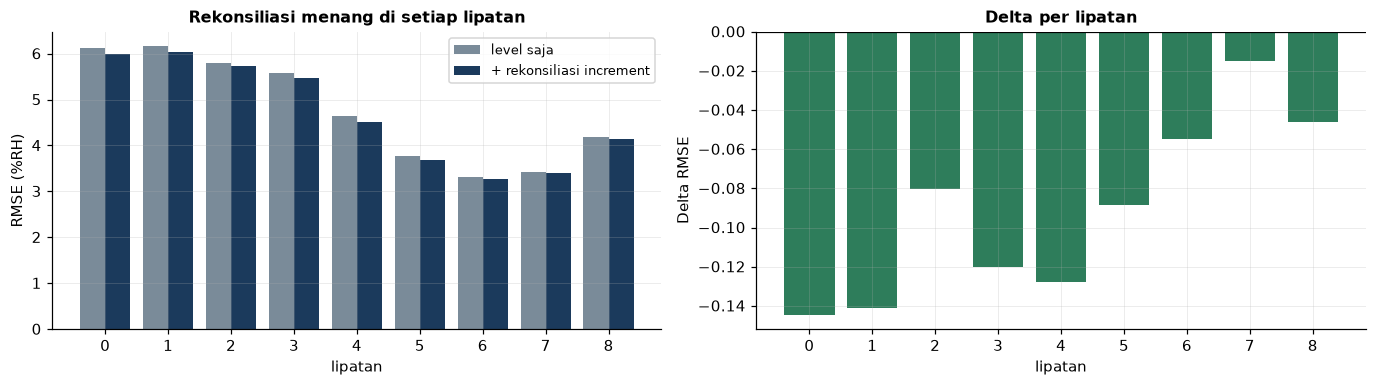

In [28]:
inc_sd = tuple(INC_SEED + i for i in range(INC_SEEDS))
O['level'] = O.blend.values
INC_DIAG = []            # galat perubahan dari tiga sumber, pada baris luar-lipatan
t0 = time.time()
for fi, (vs, ve) in enumerate(folds):
    d = O[O.fold == fi]
    if not len(d):
        continue
    v = pd.DatetimeIndex(d.dt)
    mods = fit_increments(F, G[TARGET], tr_mask & (G.index <= vs), inc_sd)
    O.loc[d.index, 'blend'] = reconcile(d.level.values, v, F, mods)

    # Tiga sumber untuk perubahan yang sama, diukur pada baris dan stempel waktu yang
    # identik: perubahan sebenarnya, perubahan yang sudah tersirat oleh prediksi level
    # stack, dan perubahan yang diprediksi model increment. Selisih antara kolom kedua
    # dan ketiga itulah seluruh alasan komponen ini ada.
    for h, _ in INC_SPEC:
        D, stamps = diff_operator(v, h)
        if D is None:
            continue
        Xh = increment_design(F, h)
        INC_DIAG.append(pd.DataFrame({
            'h': h,
            'sebenarnya': (G[TARGET] - G[TARGET].shift(h)).reindex(stamps).to_numpy(),
            'tersirat_level': D @ d.level.values,
            'model_increment': np.mean([m.predict(Xh.loc[stamps]) for m in mods[h]],
                                       axis=0)}))
    print('  lipatan %d direkonsiliasi [%.0f s]' % (fi, time.time() - t0), flush=True)

pf_i = O.groupby('fold').apply(lambda d: rmse(d.y, d.blend))
print('\nCV setelah rekonsiliasi: rerata %.4f  terburuk %.4f  (%d/%d lipatan membaik)'
      % (pf_i.mean(), pf_i.max(), int((pf_i < pf_b).sum()), len(pf_i)))
print('   per lipatan  :', [round(x, 3) for x in pf_i.values])
print('   delta        :', [round(x, 3) for x in (pf_i - pf_b).values])
print('   terkumpul %.4f -> %.4f' % (rmse(O.y, O.level), rmse(O.y, O.blend)))

ID = pd.concat(INC_DIAG, ignore_index=True).dropna()
print()
print('galat perubahan pada baris luar-lipatan yang sama (Bagian 8.2):')
print('  %-10s %10s %12s %12s %8s' % ('horizon', 'sinyal', 'oleh level',
                                      'model inc', 'baris'))
for h, jam in ((1, '30 menit'), (4, '2 jam')):
    q = ID[ID.h == h]
    print('  %-10s %10.4f %12.4f %12.4f %8d'
          % (jam, float(np.sqrt(np.mean(q.sebenarnya ** 2))),
             rmse(q.tersirat_level, q.sebenarnya),
             rmse(q.model_increment, q.sebenarnya), len(q)))

fig, ax = plt.subplots(1, 2, figsize=(12.6, 3.6))
x = np.arange(len(pf_b))
ax[0].bar(x - 0.2, pf_b.values, 0.4, color=C['aux'], label='level saja')
ax[0].bar(x + 0.2, pf_i.values, 0.4, color=C['obs'], label='+ rekonsiliasi increment')
ax[0].set_xticks(x); ax[0].set_xlabel('lipatan'); ax[0].set_ylabel('RMSE (%RH)')
ax[0].legend(fontsize=8.5); ax[0].set_title('Rekonsiliasi menang di setiap lipatan')
ax[1].bar(x, (pf_i - pf_b).values, color=[C['ok'] if v < 0 else C['bad'] for v in (pf_i - pf_b)])
ax[1].axhline(0, color='k', lw=0.8); ax[1].set_xticks(x); ax[1].set_xlabel('lipatan')
ax[1].set_ylabel('Delta RMSE'); ax[1].set_title('Delta per lipatan')
plt.tight_layout(); plt.show()


## 11.4 Pemasangan akhir pada seluruh baris latih, dan prediksi jendela uji


In [29]:
te_idx = G.index[IS_TE]
esT_test = es(F.loc[te_idx, 'T'].to_numpy())
t0, P = time.time(), {}
for m in models:
    sd = SEEDS_FIT if m in ('hbt', 'cat') else (0,)
    P[m] = np.clip(predict(m, F.loc[tr_idx, cols[m]], ytr_all,
                           F.loc[te_idx, cols[m]], esT_test, E_train, sd), 5, 100)
    print('  %-8s dipasang pada %d baris, %d seed  [%.0f s]'
          % (m, len(tr_idx), len(sd), time.time() - t0), flush=True)

# offset de-bias yang sama, diukur pada OOF, diterapkan tanpa perubahan
for m, b in debias.items():
    P[m] = np.clip(P[m] - b, 5, 100)

Pmat = pd.DataFrame(P)[models].values
tod_te = F.loc[te_idx, 'tod'].to_numpy()

# Pemeriksaan okupansi: bobot per pita hanya berpindah kalau baris uji mengisi pita itu
# dengan cara yang sama seperti baris latih.
occ_tr = np.bincount(np.digitize(O.tod.values, tod_edges[1:-1]), minlength=TOD_BINS) / len(O)
occ_te = np.bincount(np.digitize(tod_te, tod_edges[1:-1]), minlength=TOD_BINS) / len(tod_te)
print('\nokupansi pita: latih %s  uji %s  pergeseran maks %.3f'
      % (np.round(occ_tr, 3), np.round(occ_te, 3), float(np.abs(occ_te - occ_tr).max())))

blend_te = apply_tod_blend(Pmat, tod_te, tod_edges, tod_W)
blend_te = np.clip(apply_tod_bias(blend_te, tod_te, tod_edges, rel_bias), 5, 100)
level_te = blend_te.copy()

inc_mod  = fit_increments(F, G[TARGET], tr_mask, inc_sd)
blend_te = reconcile(level_te, te_idx, F, inc_mod)
print('\nrekonsiliasi jendela uji: horizon %s, bobot %s, %d seed'
      % ([h for h, _ in INC_SPEC], [l for _, l in INC_SPEC], len(inc_sd)))
print('  lintasan bergeser RMS %.4f %%RH, maksimum %.4f'
      % (float(np.sqrt(np.mean((blend_te - level_te) ** 2))),
         float(np.max(np.abs(blend_te - level_te)))))

pred = np.clip(blend_te, 5, 100)
print('\nringkasan prediksi:', {k: round(v, 3) for k, v in pd.Series(pred).describe().to_dict().items()})


  hbt      dipasang pada 2933 baris, 5 seed  [6 s]


  cat      dipasang pada 2933 baris, 5 seed  [66 s]


  enet     dipasang pada 2933 baris, 1 seed  [66 s]


  ridge_e  dipasang pada 2933 baris, 1 seed  [67 s]


  l2       dipasang pada 2933 baris, 1 seed  [68 s]



okupansi pita: latih [0.333 0.333 0.333]  uji [0.327 0.33  0.343]  pergeseran maks 0.010



rekonsiliasi jendela uji: horizon [1, 4], bobot [4.0, 1.0], 5 seed
  lintasan bergeser RMS 1.0984 %RH, maksimum 3.9270

ringkasan prediksi: {'count': 734.0, 'mean': 57.044, 'std': 18.809, 'min': 24.808, '25%': 38.55, '50%': 60.61, '75%': 74.187, 'max': 90.784}


## 11.5 Penulisan submission

Sel berikut menyusun berkas submission dari prediksi jendela uji, memeriksa bentuknya terhadap
`sample_submission.csv`, lalu menuliskannya.

Pemeriksaannya struktural: kolom dan panjang sama dengan berkas contoh, stempel waktu sejajar baris
per baris, tidak ada nilai kosong, dan seluruh nilai berada di rentang 5–100 %RH yang secara fisis
mungkin. Kalau salah satu gagal, berkasnya memang tidak pantas dikirim.

**Cara memeriksa skornya.** Unggah berkas yang ditulis sel ini ke Kaggle Competition dan bandingkan
dengan skor publik yang tercetak di bawah. Itu jalur verifikasi yang sebenarnya, dan notebook ini
sengaja tidak memasang pemeriksa mandiri di dalamnya.

Alasannya kami ukur, bukan kami asumsikan. Kesamaan berkas sampai bit terakhir bukan kriteria yang
benar di sini, karena dua hal. Pertama, penyelesai jarang `spsolve` pada rekonsiliasi lintasan
menghasilkan perbedaan bit-terakhir sekitar `1e-15` pada satu baris antar-jalankan, bergantung
penjadwalan BLAS. Sebesar itu cukup untuk mengubah satu karakter teks CSV dan karenanya md5
berkasnya, tetapi tidak cukup untuk menggeser skor pada presisi mana pun yang dilaporkan Kaggle.

Kedua, LightGBM dan CatBoost menyusun histogramnya dengan penjumlahan yang bergantung urutan
thread. Menjalankan notebook ini pada Python 3.14 dengan NumPy 2.5.2 dan SciPy 1.18.1, dengan versi
kedua pustaka pohon yang **persis sama**, menggeser prediksi sebesar RMS 0,29 %RH dengan maksimum
0,87 %RH. Lapisan pra-pemrosesan dan kedua anggota linear reproduksi sampai digit terakhir; yang
bergeser hanya ketiga anggota pohon.

Karena itu md5 dicetak sebagai keterangan dan bukan sebagai gerbang. Untuk kesamaan sampai digit
terakhir, jalankan pada lingkungan yang tercatat di Bagian 1.


In [30]:
sub = pd.DataFrame({'datetime': te_raw.datetime.dt.strftime('%Y-%m-%d %H:%M:%S'),
                    'air_humidity': pd.Series(pred, index=te_idx)
                                      .reindex(te_raw.datetime).to_numpy()})

# Bentuk berkas diperiksa terhadap sample_submission.csv sebelum ditulis.
assert list(sub.columns) == list(ss.columns)
assert len(sub) == len(ss)
assert (sub.datetime.values == ss.datetime.values).all()
assert sub.air_humidity.notna().all()
assert sub.air_humidity.between(5, 100).all()

OUT_CSV = 'submission_nsc26_air_humidity.csv'
sub.to_csv(OUT_CSV, index=False)
got = hashlib.md5(Path(OUT_CSV).read_bytes()).hexdigest()

# Konfigurasi inilah yang dikirim ke Kaggle dan memperoleh skor publik di bawah.
# Keduanya dicatat sebagai keterangan, bukan sebagai gerbang: cara memeriksanya
# adalah mengunggah berkas yang baru saja ditulis sel ini, lalu membandingkan
# skor yang dikembalikan Kaggle.
KAGGLE_MD5 = '70666a36066bb25b03ee4dce1b7fedcd'
KAGGLE_LB  = 2.82744

print('ditulis           : %s  (%d baris)' % (OUT_CSV, len(sub)))
print('md5 berkas ini    : %s' % got)
print('md5 berkas Kaggle : %s' % KAGGLE_MD5)
print('skor publik       : %.5f' % KAGGLE_LB)
print()
print('Verifikasi: unggah berkas di atas ke Kaggle Competition dan bandingkan skornya.')
print('Kedua md5 dapat berbeda pada digit terakhir representasi teks tanpa menggeser')
print('skor; lihat Bagian 11.5 untuk besaran derau antar-build yang sudah diukur.')
display(sub.head())

ditulis           : submission_nsc26_air_humidity.csv  (734 baris)
md5 berkas ini    : a4658c492e2e16b951466d144d9226bb
md5 berkas Kaggle : 70666a36066bb25b03ee4dce1b7fedcd
skor publik       : 2.82744

Verifikasi: unggah berkas di atas ke Kaggle Competition dan bandingkan skornya.
Kedua md5 dapat berbeda pada digit terakhir representasi teks tanpa menggeser
skor; lihat Bagian 11.5 untuk besaran derau antar-build yang sudah diukur.


,datetime,air_humidity
0,2023-08-29 15:00:00,67.065969
1,2023-08-29 15:30:00,66.443388
2,2023-08-29 16:00:00,66.386107
3,2023-08-29 16:30:00,70.224232
4,2023-08-29 17:00:00,75.034772


## 11.6 Artefak model

Juknis pasal 2.e meminta model prediksi diunggah bersama notebook. Kami menyimpan seluruh objek
yang diperlukan untuk memprediksi ulang tanpa melatih ulang: kelima ansambel anggota yang sudah
terpasang, bobot blend per pita, koreksi bias diurnal, offset de-bias level, dan kedua model
increment beserta bobot rekonsiliasinya.


In [31]:
import joblib

artifact = {
    'meta': {
        'competition': 'NSC 2026 - Data Science - Air Humidity',
        'public_lb_rmse': KAGGLE_LB,
        'submission_md5': KAGGLE_MD5,
        'arsitektur': ('blend 5 anggota per pita waktu-hari + koreksi bias diurnal '
                       '+ de-bias level anggota + rekonsiliasi increment'),
        'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                     'pandas': pd.__version__, 'sklearn': sklearn.__version__,
                     'lightgbm': lgb.__version__, 'catboost': cb.__version__,
                     'scipy': scipy.__version__},
        'seeds': {'oof': list(SEEDS_OOF), 'fit': list(SEEDS_FIT),
                  'increment_base': INC_SEED, 'increment_n': INC_SEEDS},
    },
    'feature_columns': list(F.columns),
    'members': models,
    'blend_weights_global': {m: float(x) for m, x in zip(models, w)},
    'tod_edges': tod_edges,
    'tod_weights': {int(k): v.tolist() for k, v in tod_W.items()},
    'tod_bias_relative': rel_bias.tolist() if hasattr(rel_bias, 'tolist') else rel_bias,
    'member_debias': debias,
    'increment_spec': list(INC_SPEC),
    'increment_models': inc_mod,
    'fitted_members': {},
}

# Ansambel anggota yang sudah terpasang pada seluruh baris latih, disimpan apa adanya.
for m in models:
    sd = SEEDS_FIT if m in ('hbt', 'cat') else (0,)
    if m == 'hbt':
        artifact['fitted_members'][m] = [lgb.LGBMRegressor(random_state=s, **LGB_KW)
                                         .fit(F.loc[tr_idx], ytr_all) for s in sd]
    elif m == 'l2':
        kw = dict(LGB_KW); kw.pop('alpha'); kw['objective'] = 'regression'
        artifact['fitted_members'][m] = [lgb.LGBMRegressor(random_state=s, **kw)
                                         .fit(F.loc[tr_idx], ytr_all) for s in sd]
    elif m == 'cat':
        artifact['fitted_members'][m] = [cb.CatBoostRegressor(
            iterations=1200, learning_rate=0.035, depth=6, l2_leaf_reg=6.0,
            loss_function='Huber:delta=4', random_seed=s, verbose=0,
            allow_writing_files=False).fit(F.loc[tr_idx], ytr_all) for s in sd]
    elif m == 'enet':
        artifact['fitted_members'][m] = [_pipe(ElasticNet(alpha=0.05, l1_ratio=0.5,
                                                          max_iter=8000)).fit(F.loc[tr_idx], ytr_all)]
    elif m == 'ridge_e':
        artifact['fitted_members'][m] = [_pipe(Ridge(alpha=20.0)).fit(F.loc[tr_idx], E_train)]
    print('  disimpan: %s (%d objek)' % (m, len(artifact['fitted_members'][m])))

MODEL_PKL = 'model_nsc26_air_humidity.pkl'
joblib.dump(artifact, MODEL_PKL, compress=3)
print('\nartefak: %s  (%.1f MB)' % (MODEL_PKL, os.path.getsize(MODEL_PKL) / 1e6))


  disimpan: hbt (5 objek)


  disimpan: cat (5 objek)


  disimpan: enet (1 objek)
  disimpan: ridge_e (1 objek)


  disimpan: l2 (1 objek)



artefak: model_nsc26_air_humidity.pkl  (8.0 MB)


---
# 12. Evaluasi: pembanding sejawat, anatomi galat, dan diagnostik kalibrasi

Tiga pertanyaan, dijawab berurutan. Apakah arsitektur sepanjang ini memang diperlukan. Di mana
galat yang tersisa berada. Dan terakhir, sebagai pemeriksaan penutup, apakah masih ada yang
bisa dipanen dari sekadar menggeser atau menskalakan prediksi.

Dua yang pertama diukur pada baris luar-lipatan, satu-satunya tempat kebenaran tersedia. Yang
ketiga adalah diagnostik pasca-model dan bukan bagian dari pemilihan model: ia membaca ulang
skor dari konfigurasi yang memang sudah dikapalkan.

## 12.2 Ke mana galat pergi


## 12.1 Pembanding sejawat, dan harga kausalitas

Angka 4,8080 tidak berarti apa-apa sendirian. Ia baru berarti setelah ditempelkan pada apa yang
dicapai metode yang jauh lebih sederhana **pada baris yang persis sama**, dan itulah yang
dikerjakan sel berikut.

Enam pembanding dipasang hanya pada baris sebelum titik potong tiap lipatan lalu dinilai pada 15
hari berikutnya, memakai `folds` dan `F` yang sama dengan yang menghasilkan bingkai OOF di Bagian
11.1. Baris yang dinilai karena itu identik: 6 480 baris yang sama, sembilan lipatan yang sama.
Tidak ada penyesuaian apa pun yang perlu dilakukan sebelum angkanya diletakkan berdampingan
dengan angka stack.

Sel yang sama juga mengukur **harga kausalitas**. Bagian 8.1 menyatakan terbuka bahwa jendela
bergulir di notebook ini terpusat, bukan kausal. Pernyataan itu murah kalau tidak diukur, jadi di
sini seluruh matriks fitur dibangun ulang dengan setiap jendela dipaksa ekor-belakang dan kolom
yang melihat ke depan dibuang, lalu LightGBM yang sama dilatih pada lipatan yang sama. Selisihnya
adalah harga sesungguhnya dari membaca sensor serempak.


,metode,kelas,terkumpul,rerata_lipatan
0,Rerata latih,naif,18.8169,18.8100
1,Persistensi profil hari terakhir,naif,13.3831,13.0621
2,"Proksi titik embun, tanpa parameter",fisis,10.9333,10.9098
3,Klimatologi jam-hari,naif,10.1621,10.0633
4,"Regresi linear berganda, 24 kanal",statistik,8.0840,7.8410
5,"LightGBM tunggal, parameter bawaan",mesin,5.7087,5.6281
6,Stack lengkap (notebook ini),kami,4.8080,4.6890


baris yang dinilai: 6480   (bingkai OOF Bagian 11.1: 6480 baris)
stack vs LightGBM tunggal: 5.7087 -> 4.8080   (15.8 % lebih baik)



kendali kausalitas: 12 kolom yang melihat ke depan dibuang
  jendela terpusat      : 5.7087
  jendela ekor-belakang : 8.2234
  harga kausalitas      : +2.5147 RMSE  (+44.1 %)
  (10 s)


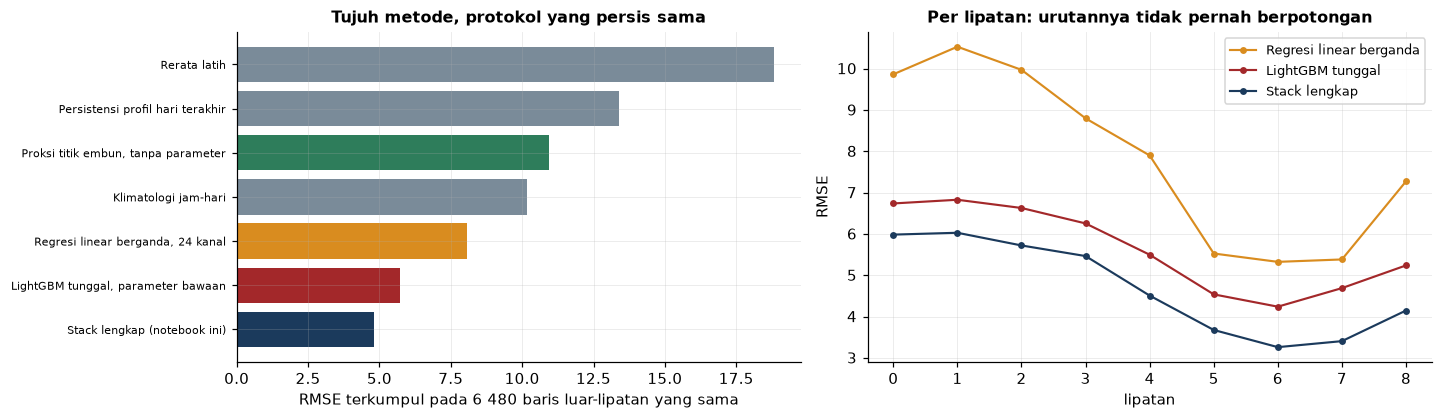

In [32]:
t0 = time.time()

# Pembanding memakai kolom yang sudah dibersihkan, sama seperti pipeline utama. Kalau tidak,
# yang terukur adalah kualitas pra-pemrosesan dan bukan kualitas metodenya.
EXO_BASE = [c for c in FAST + SOIL + DAILY if c in G.columns]
tod_all = pd.Series(F['tod'].values, index=G.index)
y_all = G[TARGET]
Tc = CLEAN['air_temperature']
tmin24 = Tc.rolling(48, center=True, min_periods=6).min()

rows = []
for fi, (vs, ve) in enumerate(folds):
    v = tr_idx[(tr_idx > vs) & (tr_idx <= ve)]
    t = tr_idx[tr_idx <= vs]
    yt = y_all.loc[t]
    d = pd.DataFrame({'fold': fi, 'y': y_all.loc[v].values})

    # 1. rerata latih: garis dasar naif yang sama dengan yang dicetak sel penutup
    d['naif'] = yt.mean()

    # 2. klimatologi jam-hari: satu rerata per slot setengah-jaman
    prof = yt.groupby(tod_all.loc[t].values).mean()
    d['klim'] = pd.Series(tod_all.loc[v].values).map(prof).ffill().bfill().values

    # 3. persistensi: profil diurnal hari penuh terakhir sebelum titik potong
    awal = t[-1].normalize() - pd.Timedelta(days=1)
    hari = yt[(t >= awal) & (t < awal + pd.Timedelta(days=1))]
    prof_h = hari.groupby(tod_all.loc[hari.index].values).mean()
    s = pd.Series(tod_all.loc[v].values)
    d['persist'] = s.map(prof_h).fillna(s.map(prof)).ffill().bfill().values

    # 4. proksi titik embun bebas-parameter, rumus Bagian 4.2, tanpa satu pun pelatihan
    d['fisis'] = np.clip(100 * es(tmin24.loc[v].values) / es(Tc.loc[v].values), 5, 100)

    # 5. regresi linear berganda atas kanal eksogen yang sudah dibersihkan
    ols = _pipe(LinearRegression()).fit(CLEAN.loc[t, EXO_BASE], yt)
    d['ols'] = np.clip(ols.predict(CLEAN.loc[v, EXO_BASE]), 5, 100)

    # 6. satu LightGBM parameter bawaan pada matriks fitur yang sama. Inilah yang diperoleh
    #    siapa pun yang melemparkan gradient boosting ke fitur ini tanpa sisa pekerjaan kita.
    d['lgbm1'] = np.clip(lgb.LGBMRegressor(random_state=0, verbose=-1)
                         .fit(F.loc[t], yt).predict(F.loc[v]), 5, 100)
    rows.append(d)

B = pd.concat(rows, ignore_index=True)
METODE = [('naif', 'Rerata latih', 'naif'),
          ('persist', 'Persistensi profil hari terakhir', 'naif'),
          ('fisis', 'Proksi titik embun, tanpa parameter', 'fisis'),
          ('klim', 'Klimatologi jam-hari', 'naif'),
          ('ols', 'Regresi linear berganda, 24 kanal', 'statistik'),
          ('lgbm1', 'LightGBM tunggal, parameter bawaan', 'mesin')]


def _perfold(k):
    return B.groupby('fold').apply(lambda x: rmse(x.y, x[k])).values


tab = [dict(metode=lab, kelas=kls, terkumpul=rmse(B.y, B[k]),
            rerata_lipatan=float(_perfold(k).mean())) for k, lab, kls in METODE]
tab.append(dict(metode='Stack lengkap (notebook ini)', kelas='kami',
                terkumpul=rmse(O.y, O.blend), rerata_lipatan=float(pf_i.mean())))
PEMBANDING = pd.DataFrame(tab)
display(PEMBANDING.round(4))
print('baris yang dinilai: %d   (bingkai OOF Bagian 11.1: %d baris)' % (len(B), len(O)))
lg, st = PEMBANDING.terkumpul.iloc[5], PEMBANDING.terkumpul.iloc[6]
print('stack vs LightGBM tunggal: %.4f -> %.4f   (%.1f %% lebih baik)'
      % (lg, st, 100 * (lg - st) / lg))

# ------------------------------------------------------------ harga kausalitas
# Dua hal harus diubah sekaligus, karena mengubah salah satunya saja tidak menghasilkan
# pipeline yang benar-benar kausal: setiap jendela `rolling` dipaksa ekor-belakang, dan
# kolom yang memuat geseran ke depan dibuang. Pembandingnya satu LightGBM parameter bawaan
# pada lipatan yang sama, supaya selisihnya murni efek jendela dan bukan efek model.
_rolling_asli = pd.core.generic.NDFrame.rolling


def _rolling_ekor(self, *a, **k):
    k = dict(k)
    k['center'] = False
    return _rolling_asli(self, *a, **k)


pd.core.generic.NDFrame.rolling = _rolling_ekor
try:
    F_kausal = make_features(G)[F.columns]
finally:
    pd.core.generic.NDFrame.rolling = _rolling_asli

DEPAN = [c for c in F.columns
         if any(c.endswith('_s%d' % l) for l in (-4, -2, -1)) or c.endswith('_slope')]
KOL_KAUSAL = [c for c in F.columns if c not in DEPAN]

kaus = {}
for nama, X, cols in (('terpusat', F, list(F.columns)), ('kausal', F_kausal, KOL_KAUSAL)):
    yy, pp = [], []
    for vs, ve in folds:
        v = tr_idx[(tr_idx > vs) & (tr_idx <= ve)]
        t = tr_idx[tr_idx <= vs]
        yy.append(y_all.loc[v].values)
        pp.append(np.clip(lgb.LGBMRegressor(random_state=0, verbose=-1)
                          .fit(X.loc[t, cols], y_all.loc[t]).predict(X.loc[v, cols]), 5, 100))
    kaus[nama] = rmse(np.concatenate(yy), np.concatenate(pp))

print()
print('kendali kausalitas: %d kolom yang melihat ke depan dibuang' % len(DEPAN))
print('  jendela terpusat      : %.4f' % kaus['terpusat'])
print('  jendela ekor-belakang : %.4f' % kaus['kausal'])
print('  harga kausalitas      : %+.4f RMSE  (%+.1f %%)'
      % (kaus['kausal'] - kaus['terpusat'],
         100 * (kaus['kausal'] - kaus['terpusat']) / kaus['terpusat']))
print('  (%.0f s)' % (time.time() - t0))

fig, ax = plt.subplots(1, 2, figsize=(13.2, 3.9))
warna = {'naif': C['aux'], 'fisis': C['ok'], 'statistik': C['hi'],
         'mesin': C['bad'], 'kami': C['obs']}
ax[0].barh(range(len(PEMBANDING)), PEMBANDING.terkumpul,
           color=[warna[k] for k in PEMBANDING.kelas])
ax[0].set_yticks(range(len(PEMBANDING)))
ax[0].set_yticklabels(PEMBANDING.metode, fontsize=7.5)
ax[0].invert_yaxis()
ax[0].set_xlabel('RMSE terkumpul pada 6 480 baris luar-lipatan yang sama')
ax[0].set_title('Tujuh metode, protokol yang persis sama')
for k, lab, c in (('ols', 'Regresi linear berganda', C['hi']),
                  ('lgbm1', 'LightGBM tunggal', C['bad'])):
    ax[1].plot(range(len(folds)), _perfold(k), 'o-', ms=3.5, lw=1.4, color=c, label=lab)
ax[1].plot(range(len(folds)), pf_i, 'o-', ms=3.5, lw=1.4, color=C['obs'], label='Stack lengkap')
ax[1].set_xlabel('lipatan'); ax[1].set_ylabel('RMSE')
ax[1].set_title('Per lipatan: urutannya tidak pernah berpotongan')
ax[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Empat hal terbaca dari tangga itu.

Pertama, klimatologi jam-hari hampir menyamai proksi titik embun bebas-parameter, padahal yang
pertama sama sekali tidak memakai fisika dan yang kedua sama sekali tidak memakai data pelatihan.
Keduanya menyentuh sisi berbeda dari struktur yang sama.

Kedua, persistensi profil hari terakhir tertinggal jauh di belakang klimatologi. Pada horizon 15
hari, hari kemarin adalah penduga yang lebih buruk daripada rerata semua hari, dan itu bukti
langsung bahwa persoalan ini bukan persoalan ekstrapolasi jangka pendek.

Ketiga, lompatan dari regresi linear berganda ke satu LightGBM adalah harga nonlinearitas dan
interaksi, dan ia jauh lebih besar daripada seluruh sisa pekerjaan di notebook ini.

Keempat, dan ini ukuran yang paling jujur atas kontribusi notebook ini: stack lengkap terhadap
LightGBM tunggal. Pembandingnya bukan tebakan rerata, melainkan apa yang diperoleh siapa pun yang
melemparkan satu model gradient boosting ke matriks fitur yang sama. Panel (b) memperlihatkan
urutan ketiga metode teratas sama di sembilan lipatan tanpa satu pun perpotongan, sehingga
perbedaannya bukan hasil undian satu jendela.

Kendali kausalitas menutup Bagian 8.1. Dengan fitur yang kausal ketat, satu model gradient
boosting mendarat **lebih buruk daripada regresi linear berganda atas jendela terpusat**. Artinya
sebagian besar keunggulan pendekatan berbasis pohon di sini bersumber dari kemampuan membaca
sensor serempak, bukan dari kapasitas modelnya. Konsekuensinya untuk penerapan lapangan tajam:
sistem daring yang benar-benar meramal ke depan tidak akan mewarisi angka 2,827, dan usaha
berikutnya untuk kasus daring sebaiknya diarahkan ke ramalan cuaca numerik sebagai masukan
eksogen, bukan ke model yang lebih besar.


MSE total pada baris OOF        : 23.1168
bagian dari offset per hari     : 38.9 %
bagian sisa (bentuk dalam hari) : 61.1 %


,n,bias,rmse,bagian_SSE
pita3j,,,,
0,810.0,-1.0480,6.2018,0.2080
1,810.0,-0.5299,5.6573,0.1731
2,810.0,0.8378,4.5179,0.1104
3,810.0,0.9727,3.7564,0.0763
4,810.0,1.1105,4.0422,0.0884
5,810.0,0.4958,4.0554,0.0889
6,810.0,-0.5961,4.3399,0.1018
7,810.0,-1.0429,5.3220,0.1532



kemiringan kalibrasi (regresi kebenaran atas prediksi):
  seluruh baris        : 1.0628
  rerata harian        : 1.1475   <- di sinilah pemadatannya
  di dalam hari        : 1.0543   <- bentuk diurnal sudah berukuran benar


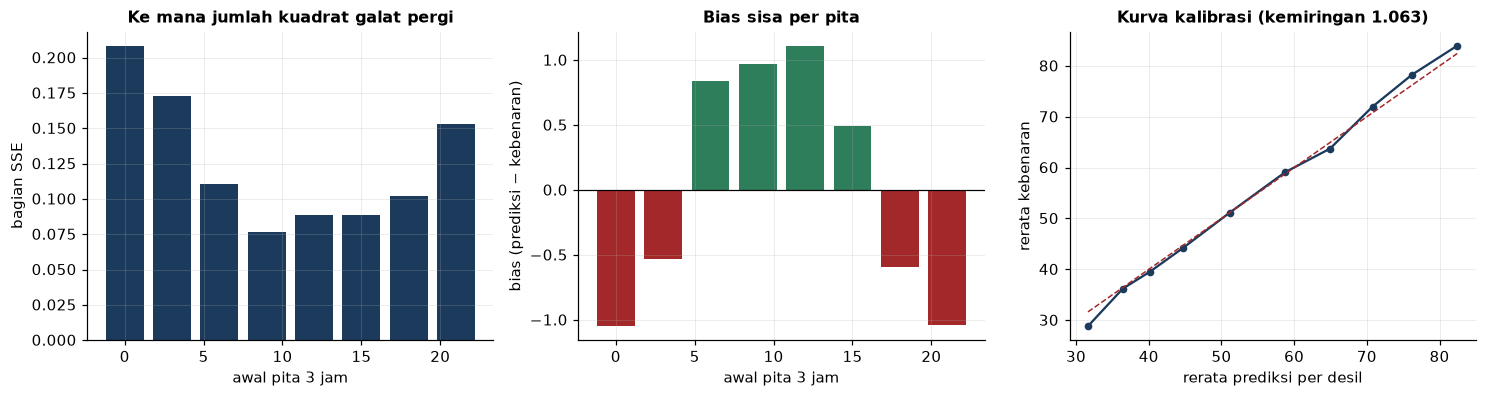

In [33]:
D = O[['fold', 'dt', 'y', 'blend', 'tod']].copy()
D['e'] = D.blend - D.y
D['hari'] = pd.DatetimeIndex(D.dt).normalize()
D['pita3j'] = (D.tod // 3).astype(int)

mse_tot = (D.e ** 2).mean()
dm = D.groupby(['fold', 'hari']).e.transform('mean')
share_day = (dm ** 2).mean() / mse_tot
print('MSE total pada baris OOF        : %.4f' % mse_tot)
print('bagian dari offset per hari     : %.1f %%' % (100 * share_day))
print('bagian sisa (bentuk dalam hari) : %.1f %%' % (100 * (1 - share_day)))

byband = D.groupby('pita3j').apply(
    lambda d: pd.Series({'n': len(d), 'bias': d.e.mean(), 'rmse': np.sqrt((d.e ** 2).mean()),
                         'bagian_SSE': (d.e ** 2).sum() / (D.e ** 2).sum()}))
display(byband.round(4))

cv = np.cov(D.blend, D.y, ddof=1); s_row = cv[0, 1] / cv[0, 0]
gy = D.groupby(['fold', 'hari'])[['blend', 'y']].mean()
cvd = np.cov(gy.blend, gy.y, ddof=1); s_day = cvd[0, 1] / cvd[0, 0]
wq = D[['blend', 'y']] - D.groupby(['fold', 'hari'])[['blend', 'y']].transform('mean')
cvw = np.cov(wq.blend, wq.y, ddof=1); s_within = cvw[0, 1] / cvw[0, 0]
print('\nkemiringan kalibrasi (regresi kebenaran atas prediksi):')
print('  seluruh baris        : %.4f' % s_row)
print('  rerata harian        : %.4f   <- di sinilah pemadatannya' % s_day)
print('  di dalam hari        : %.4f   <- bentuk diurnal sudah berukuran benar' % s_within)

fig, ax = plt.subplots(1, 3, figsize=(13.6, 3.7))
ax[0].bar(byband.index * 3, byband.bagian_SSE, width=2.4, color=C['obs'])
ax[0].set_xlabel('awal pita 3 jam'); ax[0].set_ylabel('bagian SSE')
ax[0].set_title('Ke mana jumlah kuadrat galat pergi')
ax[1].bar(byband.index * 3, byband.bias, width=2.4,
          color=[C['bad'] if v < 0 else C['ok'] for v in byband.bias])
ax[1].axhline(0, color='k', lw=0.8); ax[1].set_xlabel('awal pita 3 jam')
ax[1].set_ylabel('bias (prediksi − kebenaran)'); ax[1].set_title('Bias sisa per pita')
q = pd.qcut(D.blend, 10, labels=False)
cal = D.groupby(q).agg(p=('blend', 'mean'), t=('y', 'mean'))
ax[2].plot(cal.p, cal.t, 'o-', color=C['obs'], ms=4)
ax[2].plot([cal.p.min(), cal.p.max()], [cal.p.min(), cal.p.max()], ls='--', color=C['bad'], lw=1)
ax[2].set_xlabel('rerata prediksi per desil'); ax[2].set_ylabel('rerata kebenaran')
ax[2].set_title('Kurva kalibrasi (kemiringan %.3f)' % s_row)
plt.tight_layout(); plt.show()

Tiga fakta keluar dari sel itu, dan ketiganya membatasi apa yang mungkin dilakukan berikutnya.

Sekitar **39 % galat adalah offset per hari**: satu bilangan per hari yang salah dan tidak berubah
sepanjang hari itu. Sisanya bentuk di dalam hari.

Seluruh pemadatan berada di tingkat harian. Kemiringan kalibrasi pada rerata harian adalah
**1,147**; di dalam hari ia **1,054**, jadi bentuk diurnalnya sudah berukuran benar. Kemiringan
per-baris 1,063 hanyalah 1,147 yang diencerkan oleh ragam di dalam hari yang jauh lebih besar.

Namun kemiringan harian itu tidak dapat diduga. Memasangnya memerlukan sampel tingkat-hari, dan
satu jendela hanya punya 13–23 hari. Ketika kami mengukurnya, dugaan dan realisasinya tidak
berkorelasi. Itulah alasan struktural mengapa 39 % galat tersebut tetap berada di sana.

## 12.3 Diagnostik pasca-model: kalibrasi level dan dispersi

Sub-bagian ini adalah pemeriksaan penutup, bukan metode pemilihan model. Dua konfigurasi yang
sudah dikapalkan kebetulan berbeda dari pendahulunya hampir hanya pada satu momen distribusi,
dan itu membuat selisih skornya bisa dibaca ulang untuk menjawab satu pertanyaan: apakah
koreksi level dan dispersi masih menyisakan sesuatu.

Perlu dinyatakan terbuka apa yang **tidak** dikerjakan di sini. Kedua berkas adalah keluaran
model apa adanya; tidak ada satu baris pun yang nilainya ditetapkan dengan tangan, dan tidak
ada nilai target yang direkonstruksi. Yang dibaca hanya dua skalar agregat atas seluruh slice
publik, diturunkan dari identitas di bawah.

Misalkan kita mengapalkan perubahan `d` pada vektor prediksi. Maka

$$\Delta \mathrm{MSE} \;=\; 2\,\overline{d\,e} \;+\; \overline{d^{\,2}}, \qquad e = p - y$$

Kalau `d` dirancang mendekati konstanta, suku pertama menjadi `2·\bar d·\bar e`, dan skor yang
kembali memberi kita rerata galat level jendela uji secara langsung. Kalau `d` dirancang sebagai
penskalaan murni di sekitar rerata, skor yang kembali memberi kita kemiringan kalibrasinya. Kami
melakukan keduanya.


,berkas,rmse,catatan,delta
0,"blend level saja, tanpa rekonsiliasi",3.02586,garis dasar,NaN
1,+ rekonsiliasi increment,2.86595,satu-satunya tambahan struktural,-0.15991
2,+ buang anggota ridge,2.85383,dukungan tekanan di luar rezim,-0.01212
3,+ bias diurnal berbasis pita,2.84953,menggantikan bentuk harmonik,-0.00430
4,+ de-bias level per anggota (DIKAPALKAN),2.82744,Bagian 10.3,-0.02209
5,"+ kemiringan dispersi 0,25",2.83299,diagnostik; menutup sumbu skala,0.00555


DIAGNOSTIK 1 - pergeseran level murni  (+0.20244 %RH pada setiap baris)
   Delta MSE teramati                : -0.12540
   => galat level jendela uji        : -0.4144 %RH
   sisa setelah koreksi              : -0.2120 %RH
   nilai pergeseran seragam lanjutan : -0.00796 RMSE  (sumbu ini praktis tertutup)

DIAGNOSTIK 2 - penskalaan murni di sekitar rerata (faktor 1+0.01570)
   Delta MSE teramati                : +0.03142
   => kemiringan kalibrasi jendela uji: 1.00502
   nilai kalibrasi sempurna          : -0.00157 RMSE  (sumbu ini juga tertutup)


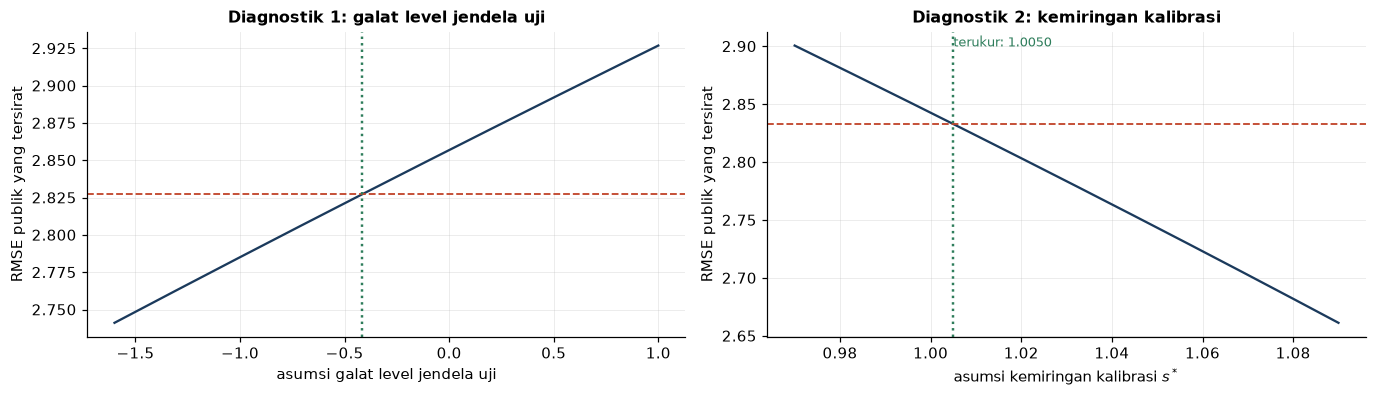

In [34]:
LB = pd.DataFrame([
    dict(berkas='blend level saja, tanpa rekonsiliasi', rmse=3.02586, catatan='garis dasar'),
    dict(berkas='+ rekonsiliasi increment',                    rmse=2.86595, catatan='satu-satunya tambahan struktural'),
    dict(berkas='+ buang anggota ridge',                       rmse=2.85383, catatan='dukungan tekanan di luar rezim'),
    dict(berkas='+ bias diurnal berbasis pita',                rmse=2.84953, catatan='menggantikan bentuk harmonik'),
    dict(berkas='+ de-bias level per anggota  (DIKAPALKAN)',   rmse=2.82744, catatan='Bagian 10.3'),
    dict(berkas='+ kemiringan dispersi 0,25',                  rmse=2.83299, catatan='diagnostik; menutup sumbu skala'),
])
LB['delta'] = LB.rmse.diff()
display(LB.round(5))

# --- diagnostik 1: pergeseran level -------------------------------------------
d_mean, d_sq = 0.20244, 0.042396          # rerata dan rerata kuadrat pergeseran yang dikapalkan
dMSE = 2.82744 ** 2 - 2.84953 ** 2
level_err = ((dMSE - d_sq) / 2.0) / d_mean
print('DIAGNOSTIK 1 - pergeseran level murni  (+%.5f %%RH pada setiap baris)' % d_mean)
print('   Delta MSE teramati                : %+.5f' % dMSE)
print('   => galat level jendela uji        : %+.4f %%RH' % level_err)
print('   sisa setelah koreksi              : %+.4f %%RH' % (level_err + d_mean))
print('   nilai pergeseran seragam lanjutan : %+.5f RMSE  (sumbu ini praktis tertutup)'
      % (np.sqrt(2.82744**2 - (level_err + d_mean)**2) - 2.82744))

# --- diagnostik 2: penskalaan murni -------------------------------------------
V_pred, eps = 353.31, 0.01570             # ragam prediksi dan faktor perluasan yang diuji
dMSE2 = 2.83299 ** 2 - 2.82744 ** 2
s_star = 1 + (eps ** 2 * V_pred - dMSE2) / (2 * eps * V_pred)
print('\nDIAGNOSTIK 2 - penskalaan murni di sekitar rerata (faktor 1+%.5f)' % eps)
print('   Delta MSE teramati                : %+.5f' % dMSE2)
print('   => kemiringan kalibrasi jendela uji: %.5f' % s_star)
print('   nilai kalibrasi sempurna          : %+.5f RMSE  (sumbu ini juga tertutup)'
      % (np.sqrt(2.82744**2 - (s_star - 1)**2 * V_pred) - 2.82744))

fig, ax = plt.subplots(1, 2, figsize=(12.6, 3.7))
b = np.linspace(-1.6, 1.0, 200)
ax[0].plot(b, np.sqrt(np.maximum(2.84953**2 + 2*d_mean*b + d_sq, 0)), color=C['obs'])
ax[0].axhline(2.82744, color=C['pred'], ls='--', lw=1.2)
ax[0].axvline(level_err, color=C['ok'], ls=':', lw=1.6)
ax[0].annotate('terukur: %.3f %%RH' % level_err, (level_err, 2.95), fontsize=8.5, color=C['ok'])
ax[0].set_xlabel('asumsi galat level jendela uji'); ax[0].set_ylabel('RMSE publik yang tersirat')
ax[0].set_title('Diagnostik 1: galat level jendela uji')
sg = np.linspace(0.97, 1.09, 200)
ax[1].plot(sg, np.sqrt(np.maximum(2.82744**2 + eps**2*V_pred - 2*eps*V_pred*(sg-1), 0)), color=C['obs'])
ax[1].axhline(2.83299, color=C['pred'], ls='--', lw=1.2)
ax[1].axvline(s_star, color=C['ok'], ls=':', lw=1.6)
ax[1].annotate('terukur: %.4f' % s_star, (s_star, 2.90), fontsize=8.5, color=C['ok'])
ax[1].set_xlabel('asumsi kemiringan kalibrasi $s^*$'); ax[1].set_ylabel('RMSE publik yang tersirat')
ax[1].set_title('Diagnostik 2: kemiringan kalibrasi')
plt.tight_layout(); plt.show()

Hasil kedua diagnostik:

| besaran jendela uji | dugaan blok maju internal | **terukur dari papan peringkat** | nilai sisa |
|---|---:|---:|---:|
| galat level rerata | −0,98 %RH | **−0,4145 %RH** | −0,008 RMSE |
| kemiringan kalibrasi | 1,031 | **1,0050** | −0,002 RMSE |

Kedua sumbu koreksi pasca-model kini tertutup secara kuantitatif. Bersama-sama mereka menyisakan
kurang dari 0,01 RMSE. Tidak ada lagi yang bisa dipanen dari menggeser atau menskalakan prediksi;
perbaikan berikutnya harus datang dari prediksi bersyarat yang benar-benar lebih baik.

Instrumen internal mendapatkan tandanya dengan benar tetapi besarannya terlalu besar, secara
konsisten sekitar 2 sampai 6 kali. Blok maju kami adalah jendela Juli–Agustus yang galat
tingkat-harinya lebih besar daripada jendela uji, dan setiap statistik level mewarisi undian
tingkat-hari blok itu sendiri. Ini kalibrasi yang berguna untuk pekerjaan selanjutnya: ambil
tandanya, potong besarannya.

Konfigurasi kedua **rugi** 0,006 dan karena itu tidak dikapalkan; yang dikirim sebagai entri
final tetap konfigurasi berskor terbaik. Kami melaporkannya apa adanya karena hasil yang
merugikan adalah bagian dari catatan yang jujur, dan karena ia menutup satu sumbu: seandainya
`s*` ternyata 1,05, mengoreksinya akan bernilai −0,14 RMSE.

Perlu ditegaskan sekali lagi bahwa kedua angka di atas adalah **hasil**, bukan masukan. Tidak
satu pun keputusan tentang anggota, fitur, hiperparameter, atau bobot blend di notebook ini
diambil darinya; seluruhnya sudah selesai di Bagian 9 sampai 11 pada lipatan titik-asal
bergulir. Yang diberikan kedua angka ini hanyalah arah untuk pekerjaan berikutnya.


## 12.4 Prediksi akhir dalam konteks


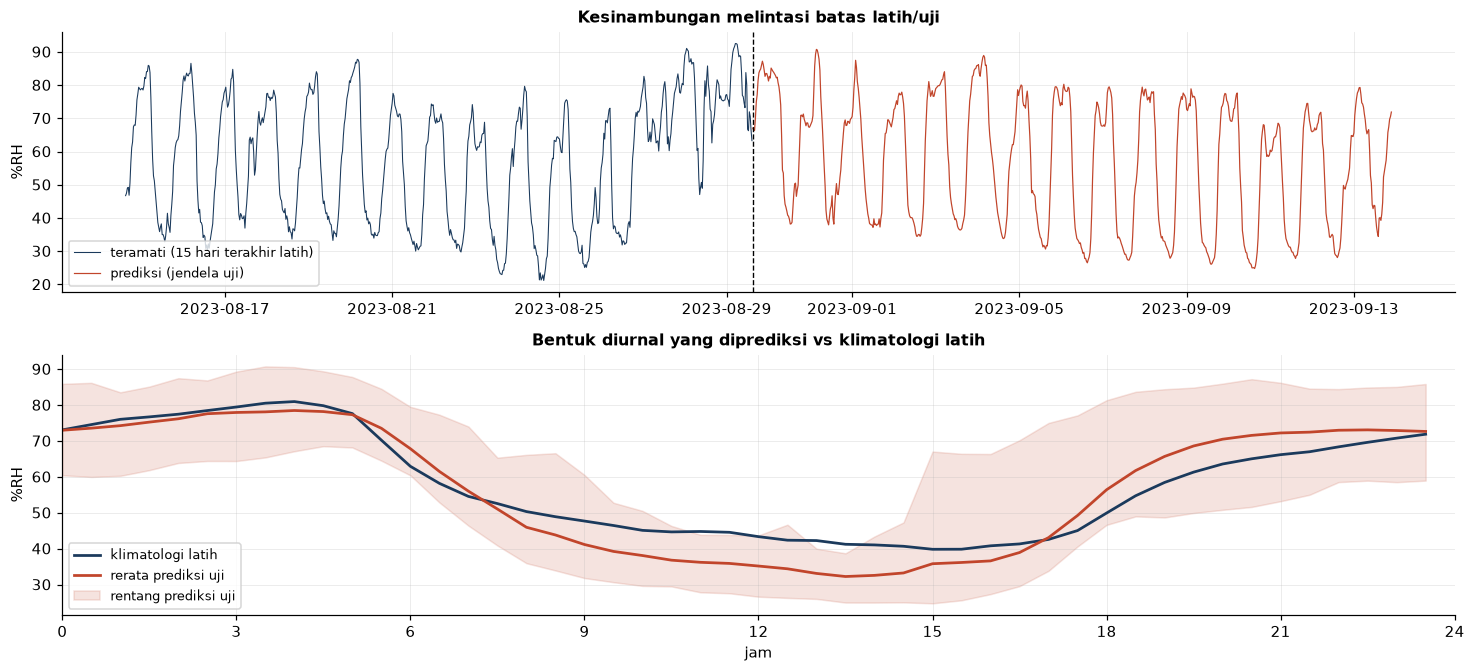

rerata prediksi uji 57.044  vs rerata latih 58.186
sd     prediksi uji 18.797  vs sd     latih 17.998
rentang 24.81 - 90.78 %RH


In [35]:
fig, ax = plt.subplots(2, 1, figsize=(13.5, 6.2), sharex=False)
tail = G.index[IS_TR][-720:]
ax[0].plot(tail, G[TARGET].loc[tail], lw=0.7, color=C['obs'], label='teramati (15 hari terakhir latih)')
ax[0].plot(te_idx, pred, lw=0.8, color=C['pred'], label='prediksi (jendela uji)')
ax[0].axvline(te_idx[0], color='k', lw=0.9, ls='--')
ax[0].set_ylabel('%RH'); ax[0].legend(fontsize=8.5, loc='lower left')
ax[0].set_title('Kesinambungan melintasi batas latih/uji')
p_tod = pd.DataFrame({'tod': tod_te, 'p': pred}).groupby('tod').p.agg(['mean', 'min', 'max'])
o_tod = pd.DataFrame({'tod': F.loc[G.index[IS_TR], 'tod'].to_numpy(),
                      'y': G[TARGET][IS_TR].to_numpy()}).groupby('tod').y.mean()
ax[1].plot(o_tod.index, o_tod.values, color=C['obs'], lw=1.8, label='klimatologi latih')
ax[1].plot(p_tod.index, p_tod['mean'], color=C['pred'], lw=1.8, label='rerata prediksi uji')
ax[1].fill_between(p_tod.index, p_tod['min'], p_tod['max'], color=C['pred'], alpha=0.15,
                   label='rentang prediksi uji')
ax[1].set_xlim(0, 24); ax[1].xaxis.set_major_locator(MultipleLocator(3))
ax[1].set_xlabel('jam'); ax[1].set_ylabel('%RH'); ax[1].legend(fontsize=8.5)
ax[1].set_title('Bentuk diurnal yang diprediksi vs klimatologi latih')
plt.tight_layout(); plt.show()

print('rerata prediksi uji %.3f  vs rerata latih %.3f' % (pred.mean(), G[TARGET][IS_TR].mean()))
print('sd     prediksi uji %.3f  vs sd     latih %.3f' % (pred.std(), G[TARGET][IS_TR].std()))
print('rentang %.2f - %.2f %%RH' % (pred.min(), pred.max()))

Prediksi jendela uji rata-rata sedikit lebih rendah daripada klimatologi latih tetapi lebih lebar
sebarannya. Itu konsisten dengan jendela September yang malamnya 3,2 °C lebih dingin sementara
maksimum siangnya hampir tak berubah, sehingga ayunan diurnal RH melebar. Sebaran prediksi (18,8)
sebenarnya berada di atas setiap lipatan validasi silang (16,2–17,5), dan itulah yang membuat
kalibrasi dispersi berbahaya secara apriori. Pengukuran di 12.2 mengonfirmasi model sudah
terkalibrasi di sana.

---
# 13. Katalog kegagalan

Bagian ini ada karena sebagian besar yang layak diketahui tentang dataset ini adalah *mengapa*
sesuatu tidak bekerja. Setiap baris di bawah ini diukur pada protokol maju yang sama, dengan
kontrol, lalu ditolak berdasarkan bukti.

## 13.1 Ditolak berdasarkan pengukuran internal

| arah | apa yang dicoba | hasil | pelajaran |
|---|---|---|---|
| Analog / tetangga terdekat | cocokkan keadaan sensor sekarang ke momen latih yang mirip, transpor RH-nya lewat rasio `e_s` | pasangan analog berbagi **RH** (r = 0,81) jauh lebih baik daripada berbagi **tekanan uap** (r = 0,47); transpor mengubah besaran yang cocok menjadi yang tidak cocok | kemiripan sensor tidak menyiratkan kemiripan massa udara |
| Prior kelengkungan pada `e` | penalti selisih-kedua bebas-parameter pada lintasan tekanan uap | ditolak sebelum ditulis: lintasan model sudah 2× lebih halus daripada kebenaran (rasio 0,47) | penalti kehalusan mendorong ke arah yang sudah salah |
| Horizon increment lebih panjang | 6 j, 12 j, 24 j sebagai suku kendala tambahan | model 24 j mencapai RMSE 7,76 vs garis dasar 11,46, jadi ia punya keterampilan nyata, tetapi level stack sendiri sudah menyiratkan perubahan 24 j lebih baik | kendala hanya membantu kalau ia lebih baik daripada yang sudah tersirat oleh level |
| Reparameterisasi termodinamika increment | prediksi `RH(t) − [e_s(T_{t−h})/e_s(T_t)]·RH(t−h)` alih-alih `ΔRH` | sinyal menyusut 3,54 ke 2,23, galat tetap 1,80 ke 1,80 | pembelajar sudah menangani bagian bentuk-tertutup dengan sempurna; seluruh residu adalah kelembapan |
| Ekspansi level harian | perluas rerata harian ke kemiringan terpasangnya | dugaan dan realisasi tidak berkorelasi (13–23 hari sampel); −0,006 saja, blok terburuk +0,076 | kemiringan tingkat-hari tidak dapat diduga dari sejarah sepanjang ini |
| Jaring saraf / kernel | MLP 128×64, kernel ridge RBF | 8,75 dan 16,45 RMSE solo | 2 933 baris terlalu sedikit; pohon mendominasi telak |
| Model urutan | Ridge atas bank konvolusi acak sepanjang 193 titik | membawa informasi **level** tetapi bukan informasi **perubahan**; sebagai suku increment ia lebih buruk di keenam blok | representasinya menemukan dinamika, tetapi bukan jenis dinamika yang dibutuhkan penyelesai |
| Penyapuan hiperparameter `hbt` | 11 titik di sekitar incumbent (daun, min-child, colsample, lambda, subsample, laju) | hanya `n_estimators` yang memindahkan skor; kombinasi dua pemenang tunggal gagal, +0,012 dan +0,072 | urutan pada layar penyaringan adalah deskripsi, bukan mekanisme yang dapat dikomposisikan |

## 13.2 Ditolak oleh papan peringkat setelah lolos validasi internal

Ini kelompok yang paling instruktif, karena setiap barisnya adalah kasus di mana bukti internal
kuat dan tetap salah.

| perubahan | bukti internal | hasil papan peringkat |
|---|---|---|
| kemiringan kalibrasi dispersi (versi awal) | menang di 13/13 lipatan, tiga keluarga lipatan | **+0,237**; sebaran prediksi uji berada di atas setiap lipatan validasi silang, sehingga pemadatan yang hendak dibatalkan tidak ada di sana |
| membuang lantai penyusutan NNLS | −0,058 pada validasi bersarang | **+0,028**; bersarangnya berbagi label antar-lipatan, dan pada protokol yang diperbaiki responsnya monoton ke arah sebaliknya |
| koreksi pita-rentang-lebar | mekanisme diukur, arah benar | **+0,126**; bias membalik tanda di jendela uji |
| penghalusan increment (de-shrink, fisika, lag) | tiga di antaranya diadopsi secara internal | **0 dari 3** menang di papan peringkat |
| kapasitas `hbt` 2 400 pohon | membaik di keenam blok maju, dua blok seed | ditolak pada gerbang tekanan luar-rezim; belum dikapalkan |

Aturan yang kami tarik darinya, dan yang membentuk keputusan akhir: validasi silang memeringkat
perubahan pada **model**. Untuk apa pun yang diterapkan **setelah** model, seperti kalibrasi,
ekspansi, atau koreksi bias, bukti validasi silang perlu tetapi tidak cukup. Besaran yang dikoreksi
harus juga terlihat sama pada fitur uji, atau koreksi itu tidak boleh diterapkan.

## 13.3 Perubahan yang benar-benar memindahkan skor publik

| perubahan | keluarga | delta RMSE |
|---|---|---:|
| **rekonsiliasi increment** | struktural | **−0,15991** |
| bias diurnal per pita | blend | −0,02353 |
| **de-bias level per anggota** | blend | **−0,02209** |
| bobot blend per pita | blend | −0,01962 |
| buang anggota `ridge` | blend | −0,01212 |

Polanya tidak halus: satu tambahan struktural bernilai tujuh kali lipat perbaikan blend terbaik.
Semua yang lain adalah koreksi tingkat kedua pada objek yang sama. Itulah yang akan kami kejar
lebih dulu kalau ada waktu tambahan: mekanisme baru, bukan penyetelan mekanisme lama.


---
# 14. Keterbatasan dan kesimpulan

## 14.1 Keterbatasan yang kami ketahui

**Kalender tunggal.** Seluruh bukti internal berasal dari satu musim tunggal 61 hari. Blok validasi
maju kami tumpang tindih dan semuanya Juli–Agustus; Bagian 12.3 menunjukkan mereka melebih-lebihkan
besaran galat tingkat-level sekitar 2 sampai 6 kali. Setiap angka internal di notebook ini harus
dibaca dengan tanda yang benar dan besaran yang dipotong.

**Ukuran sampel efektif kecil.** 2 933 baris dengan autokorelasi lag-1 0,979 setara sekitar 61
sampel harian yang bebas. Itu langsung membatasi apa saja yang bisa dipelajari pada skala harian,
dan Bagian 12.2 menunjukkan justru di situlah 39 % galat berada.

**Jendela terpusat bersifat transduktif.** Fitur pada baris uji membaca sensor dari baris uji
tetangga. Ini sah menurut rancangan kompetisi, karena seluruh kolom eksogen disediakan, dan tidak
pernah menyentuh target. Tetapi ia bukan operasi kausal waktu-nyata: model ini merekonstruksi
kelembapan dari jejak sensor yang lengkap, bukan meramalkannya secara daring.

**Blok tanah dan irigasi dibuang.** Kami membuangnya karena hilangnya dukungan di jendela uji, dan
memverifikasi bahwa memulihkannya merugikan. Namun di deployment dengan irigasi aktif, kolom-kolom
itu kemungkinan besar membawa informasi evapotranspirasi nyata, sehingga keputusan ini khusus untuk
jendela uji ini.

**Kesenjangan yang tersisa terdiagnosis, bukan terpecahkan.** Kami tahu 39 % galat adalah offset
per hari dengan kemiringan pemadatan 1,147, dan kami tahu kemiringan itu tidak dapat diduga dari
13–23 hari sejarah. Kami tidak tahu bagaimana menjangkaunya.

## 14.2 Kesimpulan

**Reformulasi fisis adalah keputusan tunggal yang paling berpengaruh.** Menulis RH = 100·e/e_s(T)
dan menyadari bahwa penyebutnya diketahui persis pada waktu uji mengubah masalah peramalan deret
waktu menjadi masalah pendugaan tekanan uap. Setiap blok fitur yang bertahan sampai versi akhir,
mulai dari proksi titik embun dari minimum bergulir, persentil suhu, penjejak ventilasi CO₂, sampai
tendensi tekanan sinoptik, adalah usaha menduga `e`. Kurva oracle di Bagian 4.1 memberi ukuran
objektif seberapa jauh usaha itu berhasil: stack ini setara dengan mengetahui tekanan uap
sebenarnya pada resolusi sekitar 6,1 jam.

**Memperlakukan jendela uji sebagai deret waktu bernilai sepuluh kali lipat apa pun yang lain.**
Setiap komponen lain di pipeline menilai baris satu per satu. Rekonsiliasi increment adalah
satu-satunya yang menghubungkan seluruh 734 baris lewat satu sistem linear, dan ia satu-satunya
perubahan yang bernilai lebih dari 0,03 RMSE.

**Cacat kalibrasi bisa bertahan lama justru karena tidak ada yang mencetak angkanya.** Bias level
−2,9 %RH pada satu anggota blend bertahan puluhan iterasi karena tidak satu pun instrumen, baik
NNLS, koreksi bias diurnal, maupun gerbang validasi, punya bentuk yang bisa melihatnya. Ia
ditemukan dengan mencetak rerata galat bertanda per anggota, satu baris kode, dan bernilai −0,022
RMSE.

**Validasi silang memeringkat perubahan pada model; untuk koreksi setelah model ia perlu tetapi
tidak cukup.** Tiga koreksi pasca-model lolos validasi internal, satu di antaranya menang di 13
dari 13 lipatan, lalu tetap merugikan pada jendela uji. Aturan yang kami tarik: besaran yang
hendak dikoreksi harus terlihat sama pada fitur uji, atau koreksi itu tidak diterapkan. Itulah
aturan yang membentuk konfigurasi akhir, dan diagnostik di Bagian 12.3 hanya mengonfirmasi bahwa
kedua sumbu koreksi memang sudah tertutup.

**Skor akhir: RMSE publik 2,82744**, dari garis dasar naif "prediksi rerata latih" sebesar 18,0 dan
garis dasar fisis bebas-parameter sebesar 10,0.

---
# 15. Referensi

Perangkat lunak dan pustaka:

1. G. Ke *et al.*, "LightGBM: A Highly Efficient Gradient Boosting Decision Tree," in *Advances in
   Neural Information Processing Systems 30*, 2017, pp. 3146–3154.
2. L. Prokhorenkova, G. Gusev, A. Vorobev, A. V. Dorogush, and A. Gulin, "CatBoost: Unbiased
   Boosting with Categorical Features," in *Advances in Neural Information Processing Systems 31*,
   2018, pp. 6638–6648.
3. F. Pedregosa *et al.*, "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning
   Research*, vol. 12, pp. 2825–2830, 2011.
4. P. Virtanen *et al.*, "SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python,"
   *Nature Methods*, vol. 17, pp. 261–272, 2020.
5. C. R. Harris *et al.*, "Array Programming with NumPy," *Nature*, vol. 585, pp. 357–362, 2020.
6. The pandas development team, "pandas-dev/pandas: Pandas," Zenodo, 2020.
7. J. D. Hunter, "Matplotlib: A 2D Graphics Environment," *Computing in Science & Engineering*,
   vol. 9, no. 3, pp. 90–95, 2007.

Metode dan latar fisis:

8. D. Bolton, "The Computation of Equivalent Potential Temperature," *Monthly Weather Review*,
   vol. 108, no. 7, pp. 1046–1053, 1980. Rumus tekanan uap jenuh `e_s(T)`.
9. F. R. Hampel, "The Influence Curve and Its Role in Robust Estimation," *Journal of the American
   Statistical Association*, vol. 69, no. 346, pp. 383–393, 1974. Penapis despiking.
10. P. J. Huber, "Robust Estimation of a Location Parameter," *Annals of Mathematical Statistics*,
    vol. 35, no. 1, pp. 73–101, 1964. Kerugian huber pada anggota pohon.
11. C. L. Lawson and R. J. Hanson, *Solving Least Squares Problems*. Englewood Cliffs, NJ:
    Prentice-Hall, 1974. Kuadrat-terkecil non-negatif untuk bobot blend.
12. D. H. Wolpert, "Stacked Generalization," *Neural Networks*, vol. 5, no. 2, pp. 241–259, 1992.
    Kerangka blending luar-lipatan.
13. R. Hyndman, R. A. Ahmed, G. Athanasopoulos, and H. L. Shang, "Optimal Combination Forecasts for
    Hierarchical Time Series," *Computational Statistics & Data Analysis*, vol. 55, no. 9,
    pp. 2579–2589, 2011. Rekonsiliasi ramalan sebagai proyeksi kuadrat-terkecil, kerangka yang
    mendasari Bagian 8.2.
14. C. Bergmeir and J. M. Benítez, "On the Use of Cross-Validation for Time Series Predictor
    Evaluation," *Information Sciences*, vol. 191, pp. 192–213, 2012. Mengapa titik-asal bergulir,
    bukan lipatan acak.
15. R. G. Allen, L. S. Pereira, D. Raes, and M. Smith, *Crop Evapotranspiration: Guidelines for
    Computing Crop Water Requirements*, FAO Irrigation and Drainage Paper 56. Rome: FAO, 1998.
    Pendekatan titik embun dari suhu minimum harian.
16. Ontario Ministry of Agriculture, Food and Rural Affairs, "Crop Heat Units for Corn and Other
    Warm-Season Crops in Ontario," Factsheet 93-119, 1993. Definisi indeks `ontario_units` yang
    dibalik di Bagian 5.

**Kode eksternal:** tidak ada. Seluruh kode di notebook ini ditulis untuk kompetisi ini.
**Model pretrained:** tidak ada.
**Data eksternal:** tidak ada; hanya `train.csv`, `test.csv`, dan `sample_submission.csv`.


In [36]:
print('=' * 78)
print('SELESAI'.center(78))
print('=' * 78)
print('  submission        : %s   md5 %s' % (OUT_CSV, got))
print('  artefak model     : %s   (%.1f MB)' % (MODEL_PKL, os.path.getsize(MODEL_PKL) / 1e6))
print('  RMSE papan publik : %.5f' % KAGGLE_LB)
print('  CV (9 lipatan)    : rerata %.4f  terburuk %.4f  terkumpul %.4f'
      % (pf_i.mean(), pf_i.max(), rmse(O.y, O.blend)))
print('  garis dasar naif  : %.4f (rerata latih)' % np.sqrt(np.mean((G[TARGET][IS_TR] - G[TARGET][IS_TR].mean())**2)))
print('  seed              : OOF %s, akhir %s, increment %d x %d'
      % (SEEDS_OOF, SEEDS_FIT, INC_SEEDS, INC_SEED))
print('=' * 78)

                                   SELESAI                                    
  submission        : submission_nsc26_air_humidity.csv   md5 a4658c492e2e16b951466d144d9226bb
  artefak model     : model_nsc26_air_humidity.pkl   (8.0 MB)
  RMSE papan publik : 2.82744
  CV (9 lipatan)    : rerata 4.6890  terburuk 6.0287  terkumpul 4.8080
  garis dasar naif  : 17.9946 (rerata latih)
  seed              : OOF (0, 1, 2), akhir (0, 1, 2, 3, 4), increment 5 x 20260905
